# Knowing When Not to Predict: A Regularised TSK Neuro-Fuzzy System with DropRule Uncertainty for Low Signal-to-Noise Stock Forecasting and Trading

**AI6124 Neuro Evolution & Fuzzy Intelligence — Group 31: Zhang Zhehao and Li Yetong**

Dataset: Waste Management, Inc. (NYSE: WM), daily, January 2000 – September 2026. Hybrid method: first-order TSK neuro-fuzzy system with DropRule.

## Abstract

Next-day stock returns have a very low signal-to-noise ratio, so flexible forecasting models easily add more noise than signal. We study this setting for Waste Management (WM) stock, with daily data from 2000 to 2026, using a first-order TSK neuro-fuzzy system trained with DropRule. Its training is adapted to weak signals by a standardised target, a penalty on the rule slopes and a shrinkage of the rule biases, and MC-DropRule, DropRule kept active at prediction time, measures the disagreement between rules. In a walk-forward evaluation over five test years (2021–2026) with five seeds, no model beats the random walk with WM's own price and volume history, but TSK ranks above the MLP and LSTM benchmarks. With S&P 500, RSG and VIX inputs, the TSK variants are the only models ahead of the random walk (by up to 0.16%, not significantly) and are significantly more accurate than both networks; daily world-news indicators from GDELT make every model less accurate. The size of the next-day return is far more predictable than its sign: on the volatility task, TSK reduces the RMSE by 1.7% relative to EWMA. In trading after 0.5% transaction costs, no strategy beats buy-and-hold (final wealth 1.43). The best prediction-based strategy, which trades only on confident MC-DropRule forecasts, reaches 1.37, while the forecast rules without this filter reach at most 1.20. For weakly predictable stocks, the value of a model therefore lies less in its forecasts than in knowing when not to act on them.

## Contents

1. [Introduction](#1.-Introduction)
2. [Literature Review](#2.-Literature-Review)
3. [Data](#3.-Data)
   - [3.1 Price Data and the Moving-Average Baseline (Part 1)](#3.1-Price-Data-and-the-Moving-Average-Baseline-(Part-1))
   - [3.2 Base Dataset: Inputs, Target and Folds](#3.2-Base-Dataset:-Inputs,-Target-and-Folds)
   - [3.3 Additional Datasets](#3.3-Additional-Datasets)
4. [Methods](#4.-Methods)
5. [Experimental Protocol](#5.-Experimental-Protocol)
6. [Results](#6.-Results)
7. [Discussion](#7.-Discussion)
8. [Future Work](#8.-Future-Work)
9. [Conclusion](#9.-Conclusion)
10. [References](#References)

## How to run this notebook

Run all cells from top to bottom in a fresh kernel, from the project folder. The data files and the saved search results used below are available in the project repository, https://github.com/Zhehao-Zhang/AI6124-WM-TSK, with the same folder structure.

- **Software.** Python 3 with NumPy, pandas, Matplotlib, scikit-learn, PyTorch, joblib and yfinance. The setup cell installs any missing core library, and the import cell shows the versions used.
- **Data.** The frozen WM price history in `data/raw/`, the S&P 500, RSG and VIX series in `data/raw/extra/` and the GDELT daily aggregates in `data/gdelt/gdelt_daily_events.csv`. Missing price files are downloaded again from Yahoo Finance, whose adjusted values may differ slightly; the GDELT file is the result of the BigQuery query of section 3.3.2.
- **Hyperparameter search.** With `RUN_SEARCH = False` (below), the search results saved in `cache/search/` are reloaded; with `True`, the search of section 5.2 is repeated (about 1–2 hours on a 16-core CPU). The final models of section 6 are always trained (about 5 minutes).
- **Parallel training.** Models are trained in parallel on the CPU with joblib; `N_JOBS` sets the number of workers.

In [1]:
# Global settings
RUN_SEARCH = False   # True: repeat the hyperparameter search of section 5.2 (about 1-2 hours); False: reload it from cache/search/
N_JOBS = 16          # parallel CPU workers for model training


# 1. Introduction

Forecasting stock prices is a standard application of computational intelligence, but next-day returns are among the hardest series to forecast: their predictable part is small compared with their daily variation, and the random walk, which forecasts tomorrow's price as today's, is difficult to beat (Fama, 1970; Welch & Goyal, 2008). In this setting, a more flexible model does not necessarily give more accurate forecasts. The question is therefore not only how accurate a model is, but whether, and when, its forecasts are worth acting on.

We study this question for Waste Management, Inc. (WM), a large US stock in a stable, non-cyclical industry, with daily data from January 2000 to September 2026. The model is a first-order Takagi–Sugeno–Kang (TSK) neuro-fuzzy system whose rule base is trained by gradient descent with DropRule (Wu et al., 2020). We adapt its training to the low signal-to-noise ratio of daily returns with a standardised target, a penalty on the rule slopes and a shrinkage of the rule biases, and we use MC-DropRule, DropRule kept active at prediction time, as a measure of model uncertainty. An MLP and an LSTM network serve as benchmarks. We ask four research questions:

- **RQ1.** Is the regularised TSK model at least as accurate as the neural networks on next-day returns, and how close do the models come to the random walk?
- **RQ2.** Does additional information, from the market (S&P 500), a peer (Republic Services, RSG), implied volatility (VIX) and world-news events (GDELT), improve the forecasts?
- **RQ3.** Which part of the next-day return is predictable: its sign, or its size?
- **RQ4.** Do the forecasts have economic value in trading, compared with strategies that use no prediction?

The contributions of this report are:
1. a training scheme for TSK systems under a low signal-to-noise ratio, whose penalties keep the forecasts close to the training mean when the signal is weak and step aside when it is strong, together with a break-even analysis of why this matters;
2. the use of MC-DropRule as a confidence filter for trading;
3. a walk-forward evaluation with five test years, five seeds, Diebold–Mariano tests and a comparison of trading with and without prediction, including the forecast-bottleneck-free framework of Ang & Quek (2006);
4. an evaluation of additional market and news data, including daily world-event indicators from GDELT.

Section 2 reviews the literature, section 3 describes the data, section 4 the models and trading rules, and section 5 the experimental protocol. Section 6 reports the results for the four research questions, section 7 discusses them, section 8 outlines future work and section 9 concludes.

# 2. Literature Review

## 2.1 From Fuzzy Sets to Trainable TSK Models

Fuzzy sets (Zadeh, 1965) describe concepts such as "high volatility" by degrees of membership instead of sharp thresholds. The first fuzzy rule-based systems were built from expert knowledge, for example the linguistic controller of Mamdani & Assilian (1975), whose rule outputs are themselves fuzzy sets. Takagi & Sugeno (1985) replaced these outputs by functions of the inputs: in a first-order TSK system, every rule has a linear consequent, and the output is the average of the rule consequents weighted by the firing strengths. This makes the system a smooth function whose parameters can be identified from data. ANFIS (Jang, 1993) wrote the TSK system as an adaptive network and trained it with a hybrid of gradient descent and least squares, which established the neuro-fuzzy approach: a fuzzy rule base learned like a neural network. Later work made the rule base itself adaptive, for example DENFIS (Kasabov & Song, 2002), which creates rules online as new data arrive.

Two problems limit these methods on larger data: grid partitions of the inputs give a number of rules that grows exponentially with the number of inputs, and batch training scales poorly. Wu et al. (2020) train TSK systems with mini-batch gradient descent and introduce DropRule, which drops randomly chosen rules during training, in analogy to dropout in neural networks (Srivastava et al., 2014). Gal & Ghahramani (2016) showed that dropout kept active at prediction time approximates Bayesian model uncertainty; our MC-DropRule applies the same idea to the rules of a TSK system.

## 2.2 Predictability of Stock Returns

The efficient-market hypothesis (Fama, 1970) states that prices reflect available information; in its weak form, past prices cannot be used to forecast future returns. The adaptive-markets hypothesis (Lo, 2004) allows predictability to appear and disappear as market conditions and participants change. Empirically, many variables that forecast returns in sample fail out of sample (Welch & Goyal, 2008), and even large machine-learning studies report monthly out-of-sample $R^2$ values below 1% for individual stocks (Gu et al., 2020). In contrast, volatility is predictable: large price changes tend to follow large changes, which ARCH and GARCH models describe (Engle, 1982; Bollerslev, 1986) and the exponentially weighted RiskMetrics estimator tracks with a single parameter (J.P. Morgan/Reuters, 1996).

## 2.3 Computational Intelligence for Stock Forecasting and Trading

Neural networks and neuro-fuzzy systems are the most common soft-computing methods for stock forecasting (Atsalakis & Valavanis, 2009). Recurrent networks, in particular the LSTM (Hochreiter & Schmidhuber, 1997), model sequences of past inputs directly. Forecasts are often evaluated by trading rules, and simple moving-average rules are a standard benchmark: Brock et al. (1992) found predictive power in such rules for the Dow Jones index over almost a century, before transaction costs. Ang & Quek (2006) combined a rough-set-based neuro-fuzzy forecaster (RSPOP) with a trading framework in which the forecast extends the price series used by a moving-average rule, so that trading signals are not limited by the accuracy of a single point forecast.

## 2.4 Additional Data for Stock Prediction

Beyond its own price history, a stock's return is related to the market, its industry and the market's expected volatility, which the VIX index measures and which is often read as investor fear (Whaley, 2000). News and sentiment have also been linked to returns: media pessimism predicts short-term price pressure (Tetlock, 2007), and Twitter mood has been reported to help forecast the Dow Jones index (Bollen et al., 2011). The GDELT database codes events reported in world news, with their location, tone and potential impact, daily since 1979 (Leetaru & Schrodt, 2013), and offers such information at global scale.

## 2.5 A Taxonomy of the Methods

The table below places the methods of this report among common approaches to next-day stock forecasting.

| Method | Model form | Learns from data | Interpretable | Uncertainty estimate | Role in this report |
|---|---|---|---|---|---|
| Random walk | $\hat{P}_t = P_{t-1}$ | – | yes | no | reference forecast |
| EWMA / GARCH | recursive variance | parameters | yes | variance forecast | volatility reference |
| Mamdani fuzzy system | expert rules, fuzzy outputs | no (or partly) | high | no | – |
| ANFIS, first-order TSK | rules with linear consequents | yes | medium | no | basis of our model |
| Self-organising neuro-fuzzy (DENFIS, RSPOP) | rule base built from data | yes | medium–high | no | DENFIS: future work; RSPOP: source of the trading framework |
| MLP | feed-forward network | yes | low | no | benchmark |
| LSTM | recurrent network | yes | low | no | benchmark |
| **TSK + DropRule + MC-DropRule (ours)** | regularised rules with linear consequents | yes | medium | rule disagreement | main model |

# 3. Data

This section has three parts:
- **3.1 Price data and the moving-average baseline (Part 1).** The sample code of Part 1, run on WM: it downloads the price history, generates moving-average crossover signals and evaluates the resulting portfolio. This strategy is the no-prediction baseline of section 6.4.
- **3.2 Base dataset.** The seven `base7` inputs, the next-day log-return target and the five expanding-window folds used by all models.
- **3.3 Additional datasets.** Market, peer and implied-volatility data (S&P 500, RSG, VIX) and world-news events (GDELT).

**Data summary.** The frozen WM snapshot contains 6,726 trading days (2000-01-03 to 2026-09-30). After the 21-day warm-up of the lagged inputs, 6,705 target dates remain (2000-02-02 to 2026-09-30). They are split into five expanding-window folds. Each fold trains on all days from 2000-02-02 up to its validation block, which is followed by a 252-day validation block and a 252-day test block; the training set grows from 5,193 days (fold 1) to 6,201 days (fold 5). The five test blocks are consecutive and together cover 1,260 trading days, from 2021-09-23 to 2026-09-30.

## 3.1 Price Data and the Moving-Average Baseline (Part 1)

Part 1 of the project provides sample code that downloads a price series from Yahoo Finance, generates trading signals from a 20/100-day simple moving-average crossover and measures portfolio performance with the multiplicative-return formula of Ang & Quek (2006). We run this code on WM. Only the data differ from the sample: the ticker (WM instead of the Keppel REIT and STI examples), a fixed period (2000-01-01 to 2026-09-30), a frozen snapshot of the Yahoo data for exact reproduction, and adjusted prices. The trading logic and its parameters (20/100 days, long/short positions, transaction rate $\delta = 0.5\%$) are those of the sample.

### Setup

The setup cell installs any missing core library, using the yfinance version of the sample code. Figures are rendered as static Matplotlib images so that they remain visible in the saved notebook; the sample's optional `mpld3` display layer and an unused `yahoofinancials` import are omitted.

In [2]:
import importlib.util
import subprocess
import sys
from importlib.metadata import version

required = {
    'numpy': 'numpy>=1.26',
    'pandas': 'pandas>=2.2',
    'matplotlib': 'matplotlib>=3.9',
    'yfinance': 'yfinance==0.2.66',
}
install = [spec for module, spec in required.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec('yfinance') is not None and version('yfinance') != '0.2.66':
    install.append('yfinance==0.2.66')
if install:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *install])
print('Core libraries are available.')


Core libraries are available.


Then we import the necessary libraries

In [3]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from IPython.display import display

%matplotlib inline
pd.plotting.register_matplotlib_converters()
pd.set_option('display.max_columns', 12)

runtime_versions = {
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'yfinance': yf.__version__,
    'matplotlib': matplotlib.__version__,
}
display(pd.Series(runtime_versions, name='Version'))


python        3.14.6
numpy          2.5.2
pandas         3.0.5
yfinance      0.2.66
matplotlib    3.11.1
Name: Version, dtype: str

### WM configuration and data loading

The configuration cell sets the ticker, the period, the moving-average windows and the transaction rate. Prices are read from the frozen snapshot `data/raw/WM_2000-01-01_2026-09-30_raw.csv`. If the file is absent, the same period is downloaded again from Yahoo Finance; the adjusted values of a new download may differ slightly.

In [4]:
TICKER = 'WM'
START_DATE = '2000-01-01'
END_DATE_INCLUSIVE = '2026-09-30'
END_DATE_EXCLUSIVE = '2026-10-01'
FAST_WINDOW = 20
SLOW_WINDOW = 100
TRANSACTION_RATE = 0.005
RUN_OPTIONAL_COMMODITY = False
DOWNLOAD_IF_MISSING = True
RAW_NAME = 'WM_2000-01-01_2026-09-30_raw.csv'
FROZEN_CSV_SHA256 = '3851c2b9ccd7e96b496a118612410d5d56b385749e02a44a4f0e4bba1e9db7c1'

def locate_project_root():
    here = Path.cwd()
    for base in [here, here / 'proj', *list(here.parents)[:3]]:
        if (base / 'data' / 'raw' / RAW_NAME).is_file():
            return base
    return here

PROJECT_ROOT = locate_project_root()
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'wm_ma_baseline'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
data_origin = None
source_csv_hash = None

def load_wm_source():
    global data_origin, source_csv_hash
    candidates = [
        PROJECT_ROOT / 'data' / 'raw' / RAW_NAME,
        Path.cwd() / RAW_NAME,
        Path('/content') / RAW_NAME,
        OUTPUT_DIR / 'downloads' / RAW_NAME,
    ]
    source_path = next((path for path in candidates if path.is_file()), None)
    if source_path is not None:
        source_csv_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
        raw = pd.read_csv(source_path, parse_dates=['Date'], index_col='Date', float_precision='round_trip')
        data_origin = 'frozen CSV' if source_csv_hash == FROZEN_CSV_SHA256 else 'other cached snapshot'
        print(f'Loaded {source_path.name}; source: {data_origin}')
    else:
        if not DOWNLOAD_IF_MISSING:
            raise FileNotFoundError(f'Upload or provide {RAW_NAME}.')
        raw = yf.Ticker(TICKER).history(
            start=START_DATE, end=END_DATE_EXCLUSIVE,
            interval='1d', auto_adjust=False, actions=True, repair=False,
            raise_errors=True,
        )
        if raw.empty:
            raise RuntimeError('Yahoo returned no WM prices.')
        raw.index = raw.index.tz_localize(None).normalize()
        raw.index.name = 'Date'
        columns = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']
        raw = raw[columns]
        download_dir = OUTPUT_DIR / 'downloads'
        download_dir.mkdir(parents=True, exist_ok=True)
        downloaded_path = download_dir / RAW_NAME
        raw.to_csv(downloaded_path)
        source_csv_hash = hashlib.sha256(downloaded_path.read_bytes()).hexdigest()
        data_origin = 'new Yahoo snapshot'
        print('Downloaded a new snapshot; adjusted values may differ slightly from the frozen baseline.')
    raw.index = pd.DatetimeIndex(raw.index).normalize()
    raw.index.name = 'Date'
    assert raw.index.is_unique and raw.index.is_monotonic_increasing
    assert raw.index.min() >= pd.Timestamp(START_DATE)
    assert raw.index.max() <= pd.Timestamp(END_DATE_INCLUSIVE)
    assert not raw[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']].isna().any().any()
    assert (raw[['Open', 'High', 'Low', 'Close', 'Adj Close']] > 0).all().all()
    return raw.copy(deep=True)

def adjusted_prices(raw):
    factor = raw['Adj Close'] / raw['Close']
    adjusted = raw.copy(deep=True)
    for column in ['Open', 'High', 'Low']:
        adjusted[column] = raw[column] * factor
    adjusted['Close'] = raw['Adj Close']
    return adjusted.drop(columns=['Adj Close'])


### 3.1.1 Download historical prices

The sample code demonstrates both `yf.download(...)` and `Ticker.history(...)`. We use one WM snapshot throughout; the equivalent download is `Ticker('WM').history(start='2000-01-01', end='2026-10-01', auto_adjust=True)`, where the exclusive end date includes 30 September 2026.

The adjustment of `auto_adjust=True` is applied to the frozen data: Open, High and Low are multiplied by Adj Close / Close, Close is replaced by Adj Close, and Volume and the corporate-action records are kept. Returns computed from adjusted closes therefore already include dividends.

#### Stock price: Waste Management (WM)

WM (NYSE, in USD) replaces the sample's Keppel REIT and STI examples. `source_df` holds the original data and `stock_df` the adjusted prices used in the rest of the notebook.

In [5]:
ticker = yf.Ticker(TICKER)
source_df = load_wm_source()
stock_df = adjusted_prices(source_df)
display(stock_df.head())
display(pd.Series({
    'Ticker': TICKER,
    'Rows': len(stock_df),
    'First trading date': str(stock_df.index.min().date()),
    'Last trading date': str(stock_df.index.max().date()),
    'Price basis': 'Yahoo adjusted OHLC, equivalent to auto_adjust=True',
    'Data origin': data_origin,
}, name='WM dataset'))


Loaded WM_2000-01-01_2026-09-30_raw.csv; source: frozen CSV


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0


Ticker                                                               WM
Rows                                                               6726
First trading date                                           2000-01-03
Last trading date                                            2026-09-30
Price basis           Yahoo adjusted OHLC, equivalent to auto_adjust...
Data origin                                                  frozen CSV
Name: WM dataset, dtype: object

The project period is fixed to January 2000 – September 2026 instead of the maximum available history, and the same data are used in all later sections.

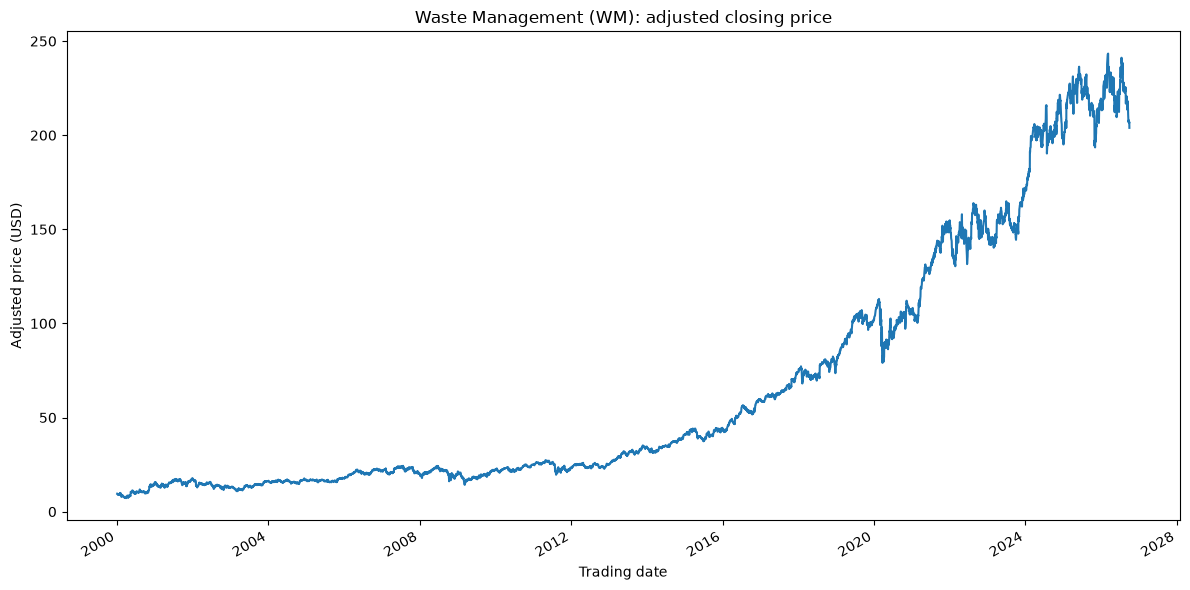

In [6]:
figure(figsize=(12, 6))
stock_df['Close'].plot(title="Waste Management (WM): adjusted closing price")
plt.ylabel('Adjusted price (USD)')
plt.xlabel('Trading date')
plt.tight_layout()
plt.show()


As in the sample's `Ticker.history` example, the table contains OHLCV, dividends and stock splits.

In [7]:
stock_df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0


You can also look at the only the dividends using the code below.

In [8]:
# Dividends paid by WM over the project period.
source_df.loc[source_df['Dividends'].ne(0), 'Dividends']


Date
2000-09-27    0.010
2001-09-25    0.010
2002-09-26    0.010
2003-09-26    0.010
2004-02-26    0.188
              ...  
2025-09-12    0.825
2025-12-05    0.825
2026-03-13    0.945
2026-06-05    0.945
2026-09-11    0.945
Name: Dividends, Length: 95, dtype: float64

#### Optional commodity example

The sample also shows gold futures (`GC=F`). The example is kept but disabled (`RUN_OPTIONAL_COMMODITY = False`); the additional datasets used in this project are described in section 3.3.

In [9]:
commodity_df = None
if RUN_OPTIONAL_COMMODITY:
    commodity_ticker = yf.Ticker('GC=F')
    commodity_df = commodity_ticker.history(
        start=START_DATE, end=END_DATE_EXCLUSIVE,
        interval='1d', auto_adjust=True, actions=True, repair=False,
    )
    display(commodity_df.head())
else:
    print('Commodity example disabled.')


Commodity example disabled.


The plot below is produced only when the commodity example is enabled.

In [10]:
if commodity_df is not None:
    figure(figsize=(12, 6))
    commodity_df['Close'].plot(title='Gold futures: optional example')
    plt.ylabel('Adjusted price (USD)')
    plt.tight_layout()
    plt.show()
else:
    print('Commodity example disabled; no figure.')


Commodity example disabled; no figure.


### 3.1.2 Computing trade signals

There are different types of moving averages, such as simple moving average, weighted moving average or exponential moving average. The
difference between the types is how the average is computed based on the weight assigned to data points. Simple moving average can be computed by simply taking the mean of the data points. The period to compute the moving average is a parameter. You can have a 200 days simple moving average, a 5 days simple moving average etc. Here' we compute a fast 20 days and slow 100 days moving average on the close price.

In [11]:
# Strategy table: a copy of the adjusted prices with the two moving averages.
df = stock_df.copy(deep=True)
df['Fast_SMA'] = df['Close'].rolling(window=FAST_WINDOW, min_periods=1).mean()
df['Slow_SMA'] = df['Close'].rolling(window=SLOW_WINDOW, min_periods=1).mean()
df.head()


,Open,High,Low,Close,Volume,Dividends,Stock Splits,Fast_SMA,Slow_SMA
Date,,,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0,9.562130,9.562130
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0,9.544930,9.544930
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0,9.550664,9.550664
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0,9.536333,9.536333
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0,9.452062,9.452062


There many moving average strategies that can be developed to generate trade signals. here we will use a simple moving average crossover strategy based on the SMAs we computed. A moving average can be use to indicate price trends. A crossover occurs when a faster or shorter moving average, such as the 20 days SMA crosses a slower or longer moving average, such as the 100 days SMA. This crossover  point can be used as a  indicator to buy or sell a stock.

First we create a new column ‘Signal’ such that if Fast_SMA is greater than Slow_SMA then set to 1 else set to 0.


In [12]:
df['Signal'] = 0.0
df['Signal'] = np.where(df['Fast_SMA'] > df['Slow_SMA'], 1.0, 0.0)

We now need to generate the buy and sell from the ‘Signal’ values. Crossover happens when the Fast_SMA and the Slow_SMA cross,  the ‘Signal’ changes from 0 to 1, or from 1 to 0. Thus we can just create a ‘Position’ value to indicate a day-to-day difference of the ‘Signal’ column.

‘Position’ = 1 implies that Signal changed from 0 to 1, meaning a faster moving average has crossed a slower moving average. This indicates a bull or up trend in the price and thus this is a buy signal.

‘Position’ = -1 implies that  Signal changed from 1 to 0, meaning a faster moving average has crossed below a slower moving average. This indicates a bear or down trend in the price and thus this is a sell signal.

In [13]:
df['Position'] = df['Signal'].diff()
# The first row has no previous signal, so no position change.
df.loc[df.index[0], 'Position'] = 0.0
df.head()


,Open,High,Low,Close,Volume,Dividends,Stock Splits,Fast_SMA,Slow_SMA,Signal,Position
Date,,,,,,,,,,,
2000-01-03,9.768507,9.837299,9.183772,9.562130,3833200,0.0,0.0,9.562130,9.562130,0.0,0.0
2000-01-04,9.527731,9.906088,9.424543,9.527731,4736900,0.0,0.0,9.544930,9.544930,0.0,0.0
2000-01-05,9.493338,9.699715,9.458942,9.562130,2676000,0.0,0.0,9.550664,9.550664,0.0,0.0
2000-01-06,9.562132,9.562132,9.183774,9.493340,2428500,0.0,0.0,9.536333,9.536333,0.0,0.0
2000-01-07,9.458940,9.493336,9.080583,9.114979,2461900,0.0,0.0,9.452062,9.452062,0.0,0.0


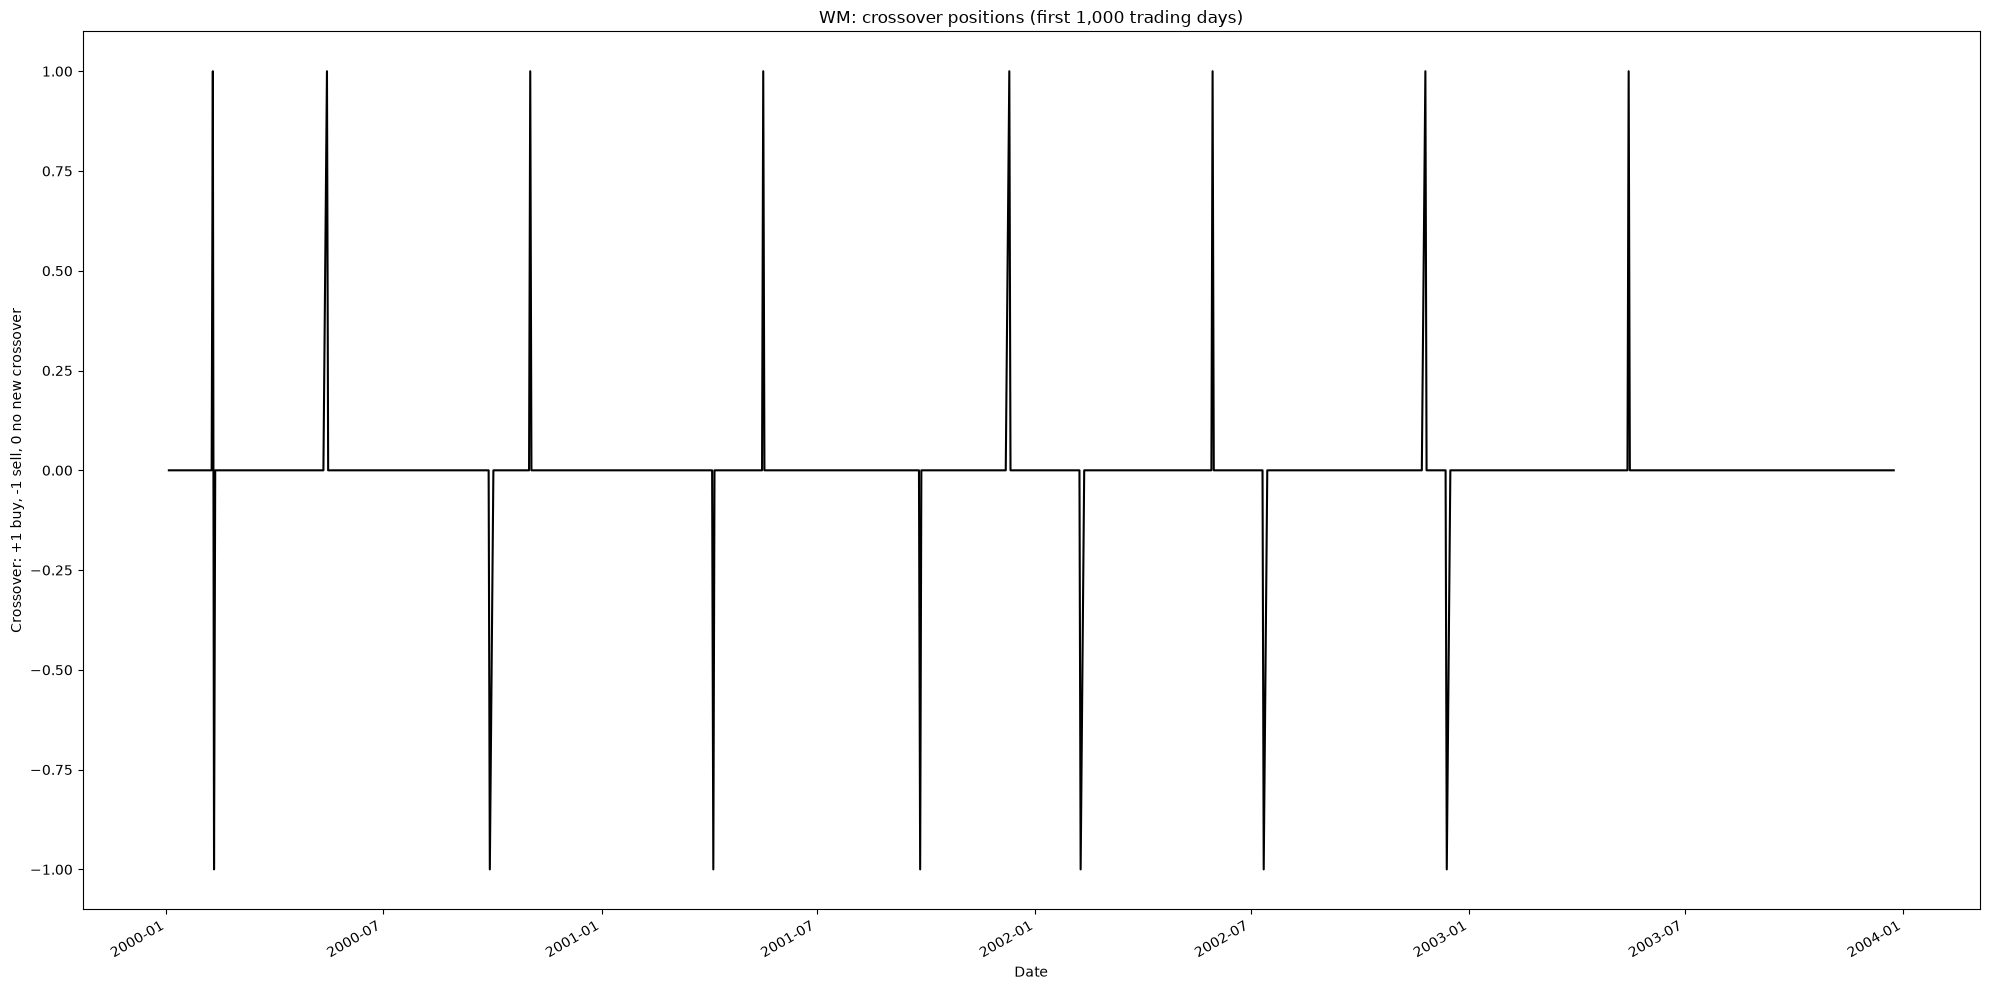

In [14]:
# Crossover positions (+1 buy, -1 sell) over the first 1,000 trading days.
plt.figure(figsize=(20, 10))
df.iloc[0:1000]['Position'].plot(color='k', label='Position')
plt.title('WM: crossover positions (first 1,000 trading days)')
plt.ylabel('Crossover: +1 buy, -1 sell, 0 no new crossover')
plt.tight_layout()
plt.show()


Following the sample, each nonzero Position is extended into a persistent Trade state: +1 is long, −1 is short, and 0 is the flat state before the first crossover. In the return formula, the previous day's Trade is applied to the next day's price change.

Initial Position: 0.0


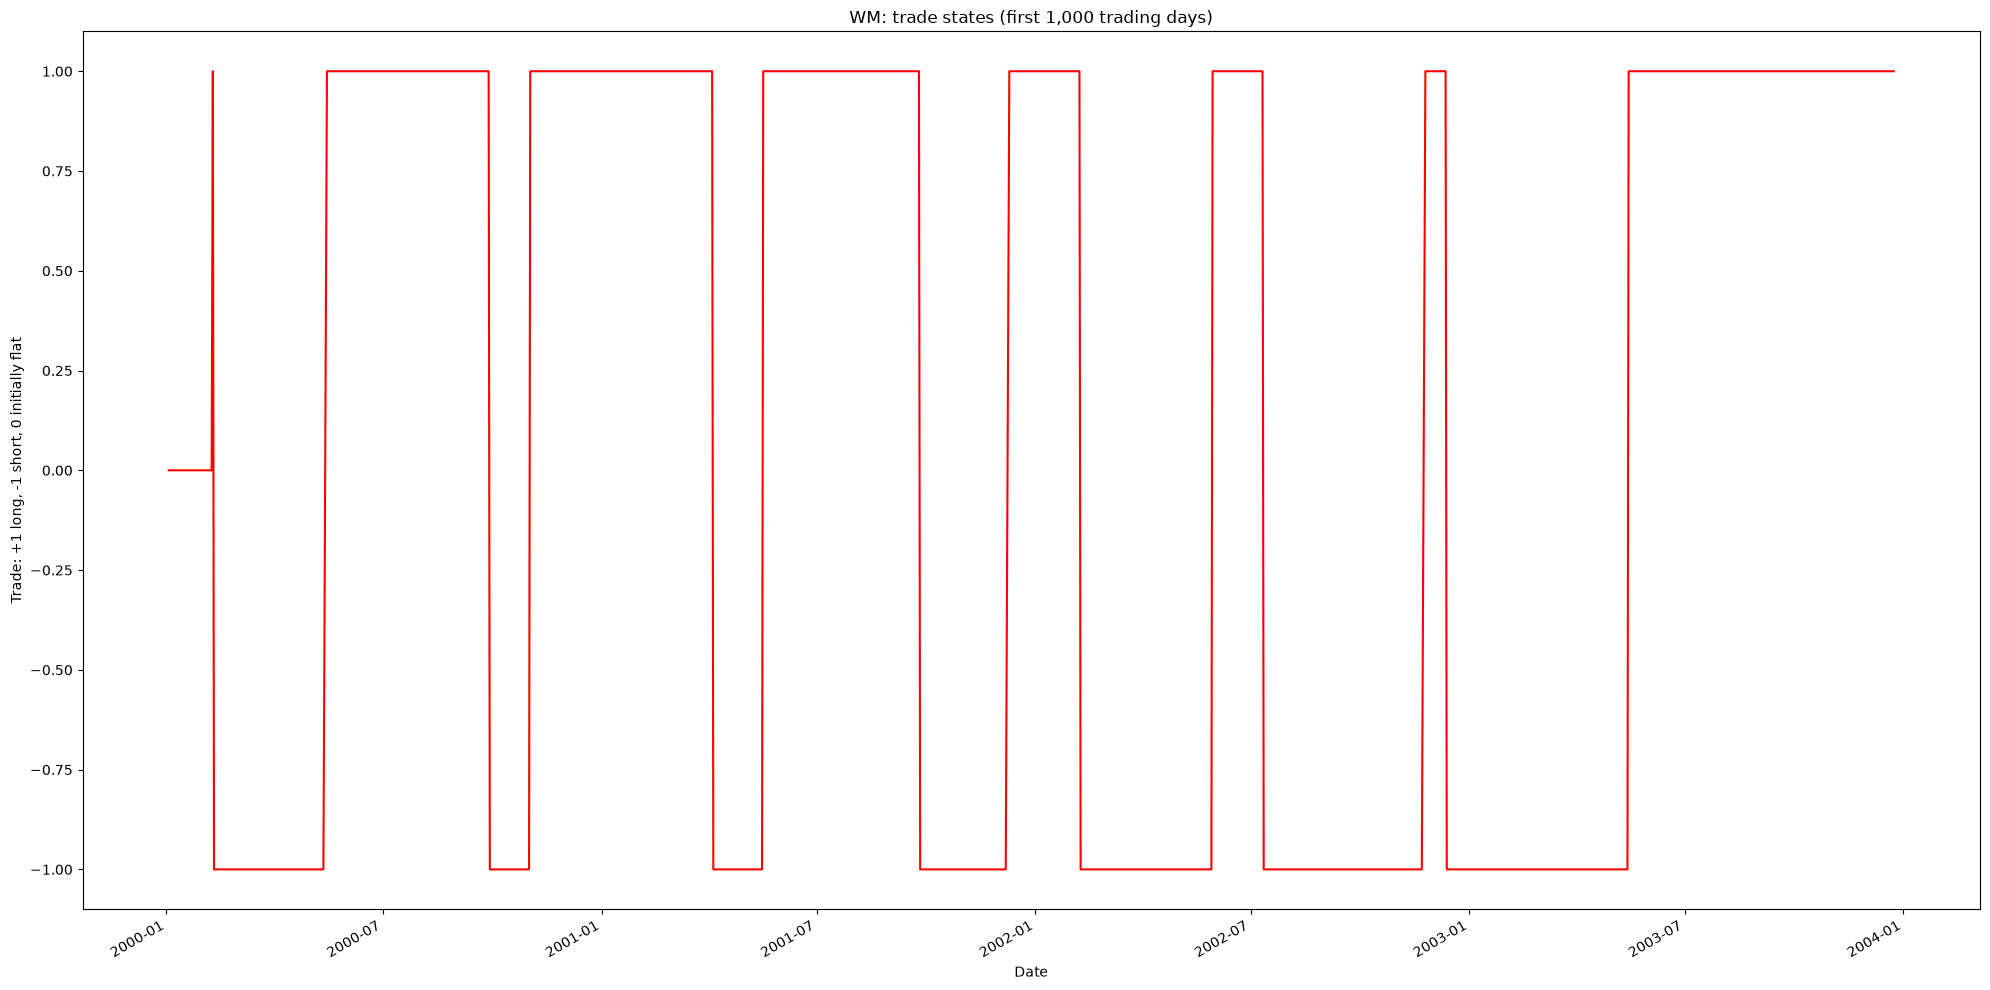

In [15]:
plt.figure(figsize=(20, 10))

# Extend each crossover (Position = +1 or -1) into a persistent long/short Trade state.
df['Trade'] = df['Position'].copy()
prevrow = df.iloc[0]
print('Initial Position:', prevrow['Position'])
for index, row in df.iloc[1:].iterrows():
    if row['Trade'] == 0:
        if prevrow['Trade'] != 0:
            df.at[index, 'Trade'] = prevrow['Trade']
            row['Trade'] = prevrow['Trade']
    prevrow = row

df.iloc[0:1000]['Trade'].plot(color='r', label='Trade')
plt.title('WM: trade states (first 1,000 trading days)')
plt.ylabel('Trade: +1 long, -1 short, 0 initially flat')
plt.tight_layout()
plt.show()


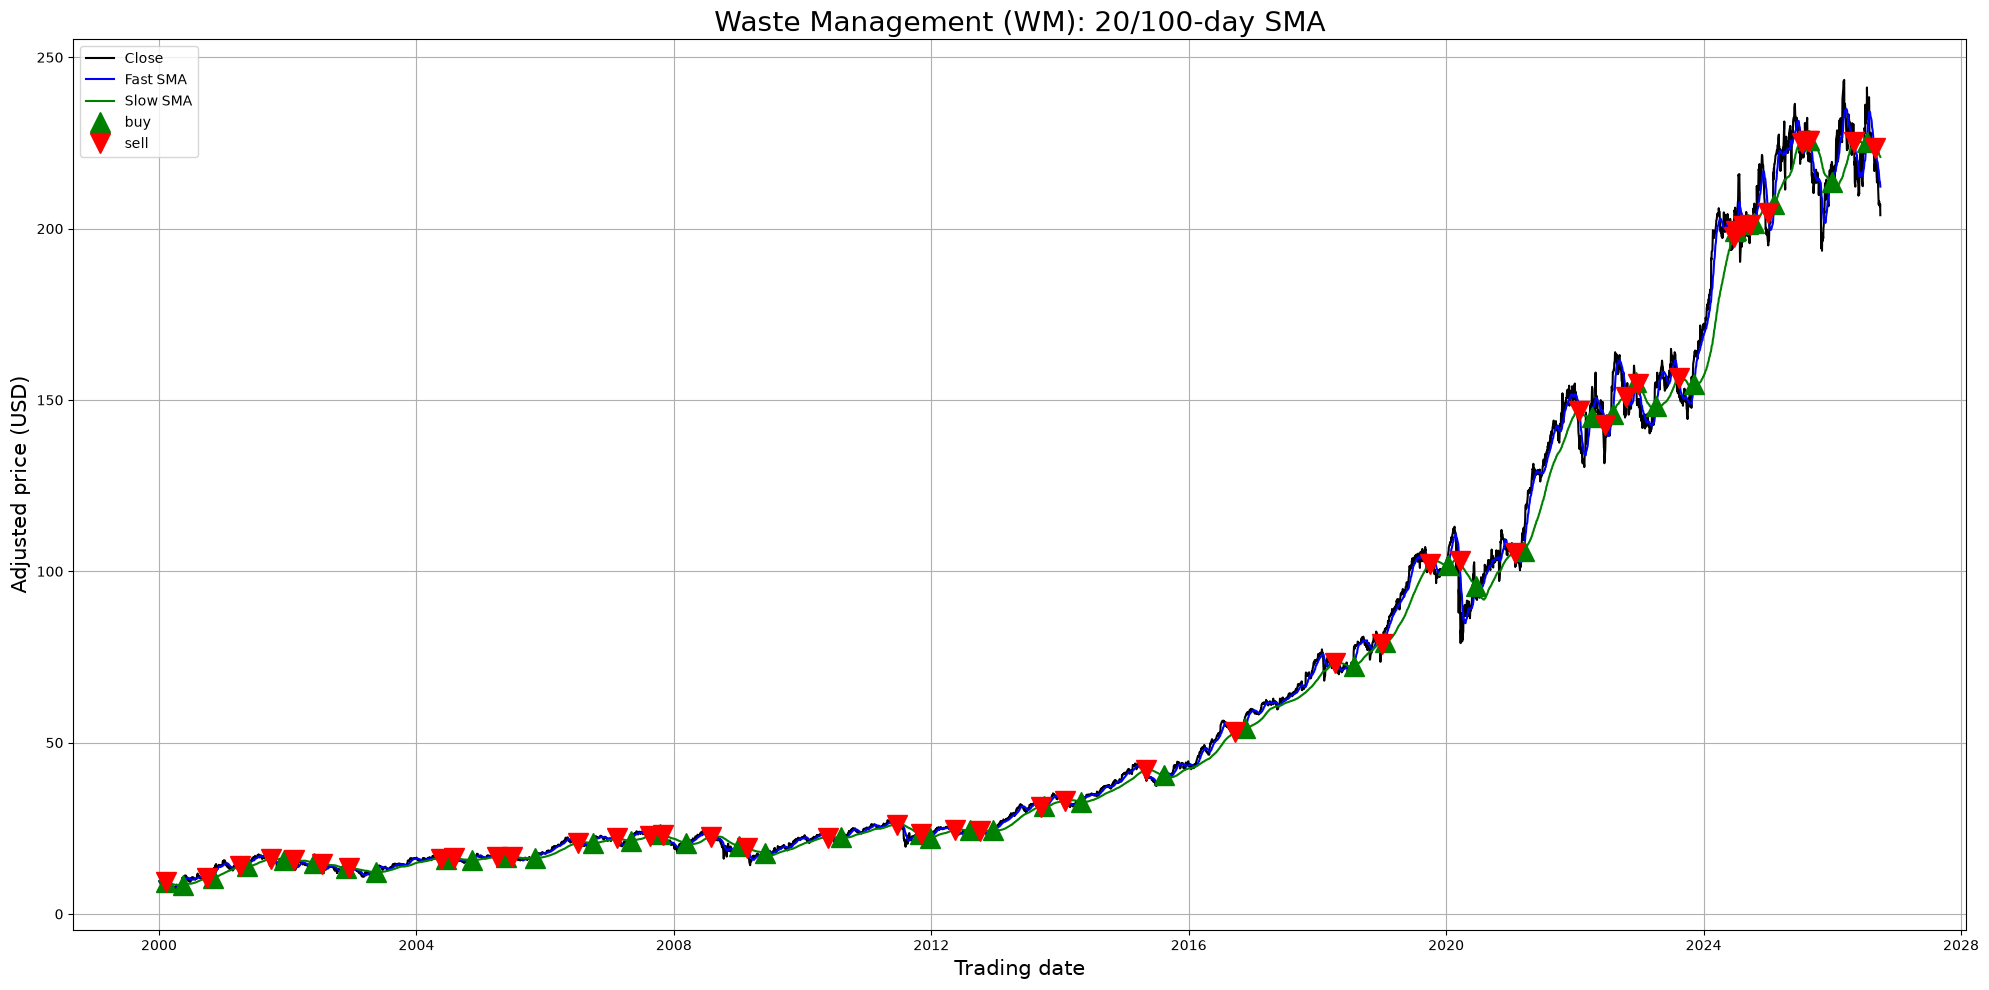

In [16]:
# Close price, the two moving averages and the crossover markers.
def plotprice(tdf):
    plt.figure(figsize=(20, 10))
    dates = tdf.index.to_pydatetime()
    plt.plot(dates, tdf['Close'].to_numpy(), color='k', label='Close')
    plt.plot(dates, tdf['Fast_SMA'].to_numpy(), color='b', label='Fast SMA')
    plt.plot(dates, tdf['Slow_SMA'].to_numpy(), color='g', label='Slow SMA')
    buys = tdf['Position'].eq(1)
    sells = tdf['Position'].eq(-1)
    plt.plot(dates[buys.to_numpy()], tdf.loc[buys, 'Fast_SMA'].to_numpy(), '^', markersize=15, color='g', label='buy')
    plt.plot(dates[sells.to_numpy()], tdf.loc[sells, 'Fast_SMA'].to_numpy(), 'v', markersize=15, color='r', label='sell')
    plt.ylabel('Adjusted price (USD)', fontsize=15)
    plt.xlabel('Trading date', fontsize=15)
    plt.title(f'Waste Management (WM): {FAST_WINDOW}/{SLOW_WINDOW}-day SMA', fontsize=20)
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

plotprice(df)


It is not very clear in the plot above since it included the prices of many years. Lets zoom in to take a closer look.

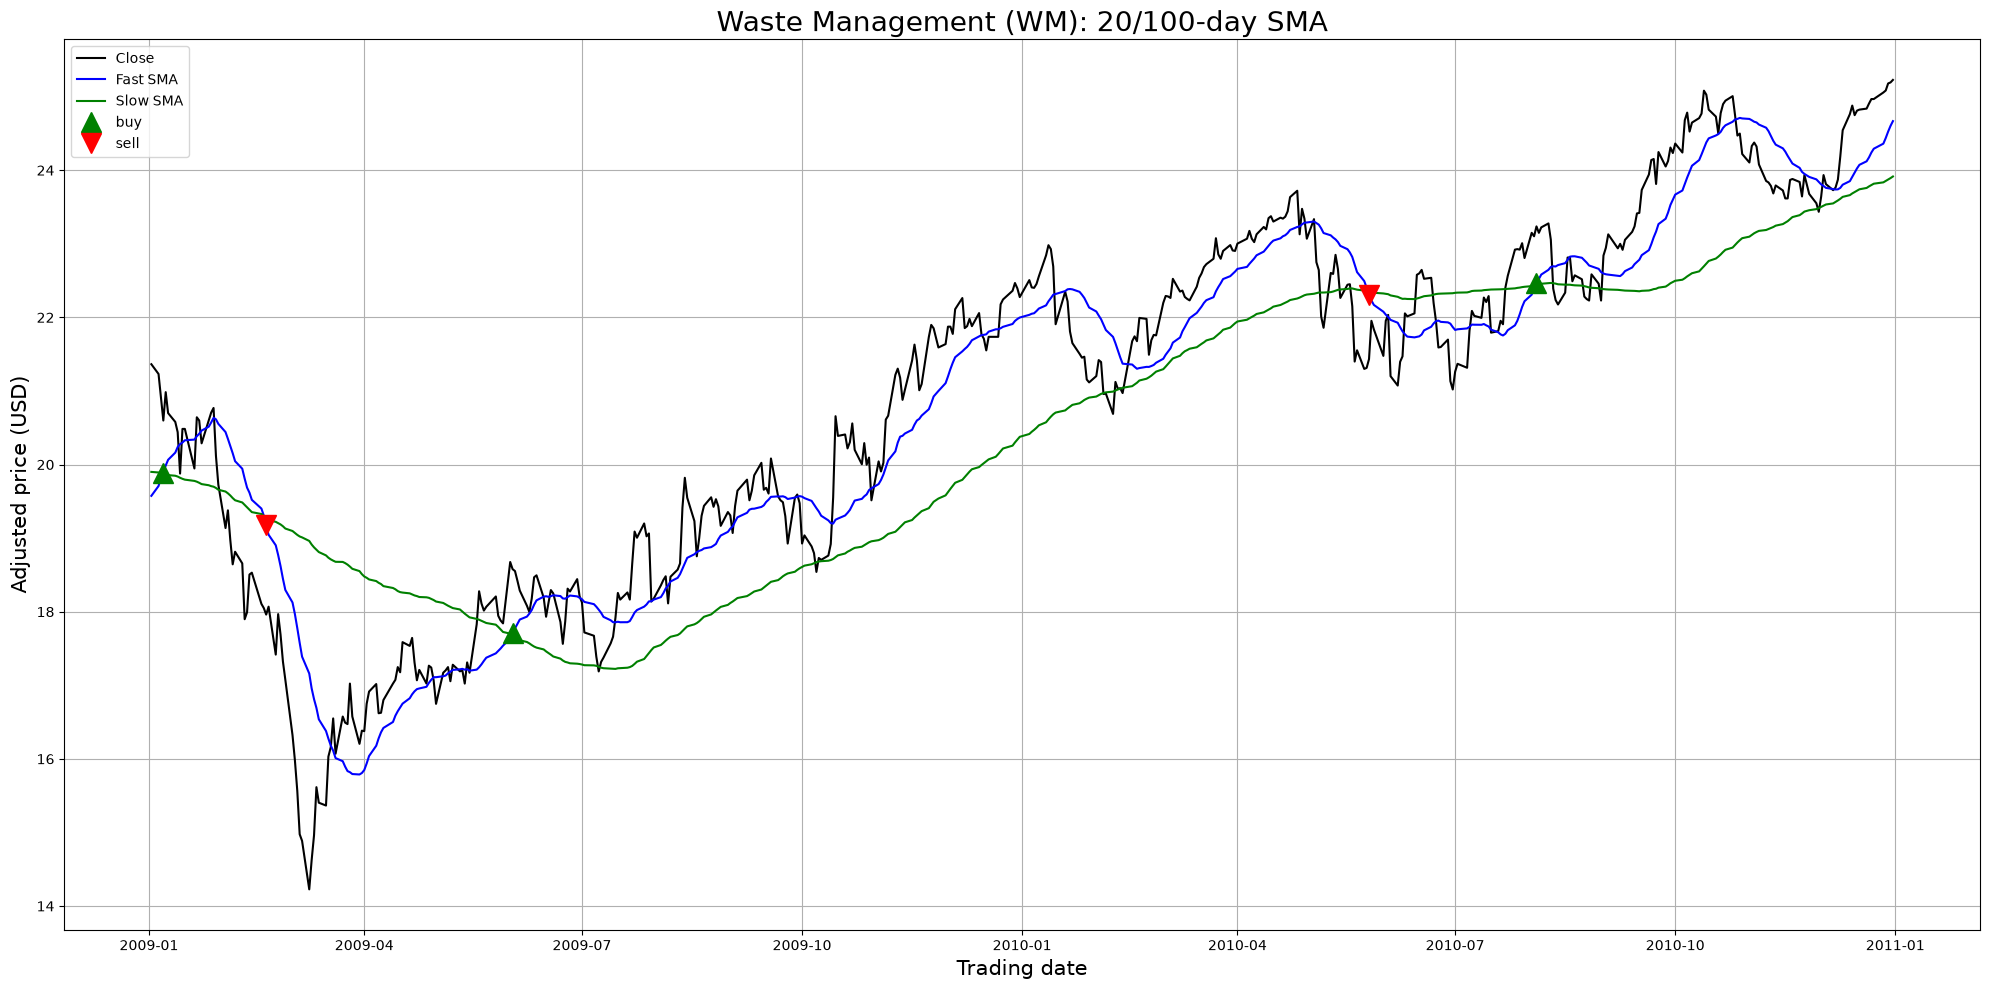

In [17]:
sdf=df.loc['2009-01-01':'2010-12-31']
plotprice(sdf)


The zoomed panel shows WM's crossovers in 2009–2010. When the two averages are close, they cross repeatedly, and the resulting trades lose money after transaction costs.

### 3.1.3 Computing portfolio returns

The computation of portfolio returns in this section is based on the multiplicative returns given by (refer equation 11 of the reference paper)

$\begin{equation}
R(T)=\{1+F(T-1)r(T)\}\{1-\delta|F(T)-F(T-1)|\}
\end{equation}$

where $r(T)=(y(T)/y(T-1))-1$; $y(T)$ is the closing price at time $T$; $F(T)$ is the action from the trading system; and $\delta$ is the transaction rate.

The multplicative profits $R$ can computed using

$\begin{equation}
R=\prod\limits_{T = 1}^{n} R(T)
\end{equation}$

where $n$ is the total number of time points.

Second-row Trade: 0.0


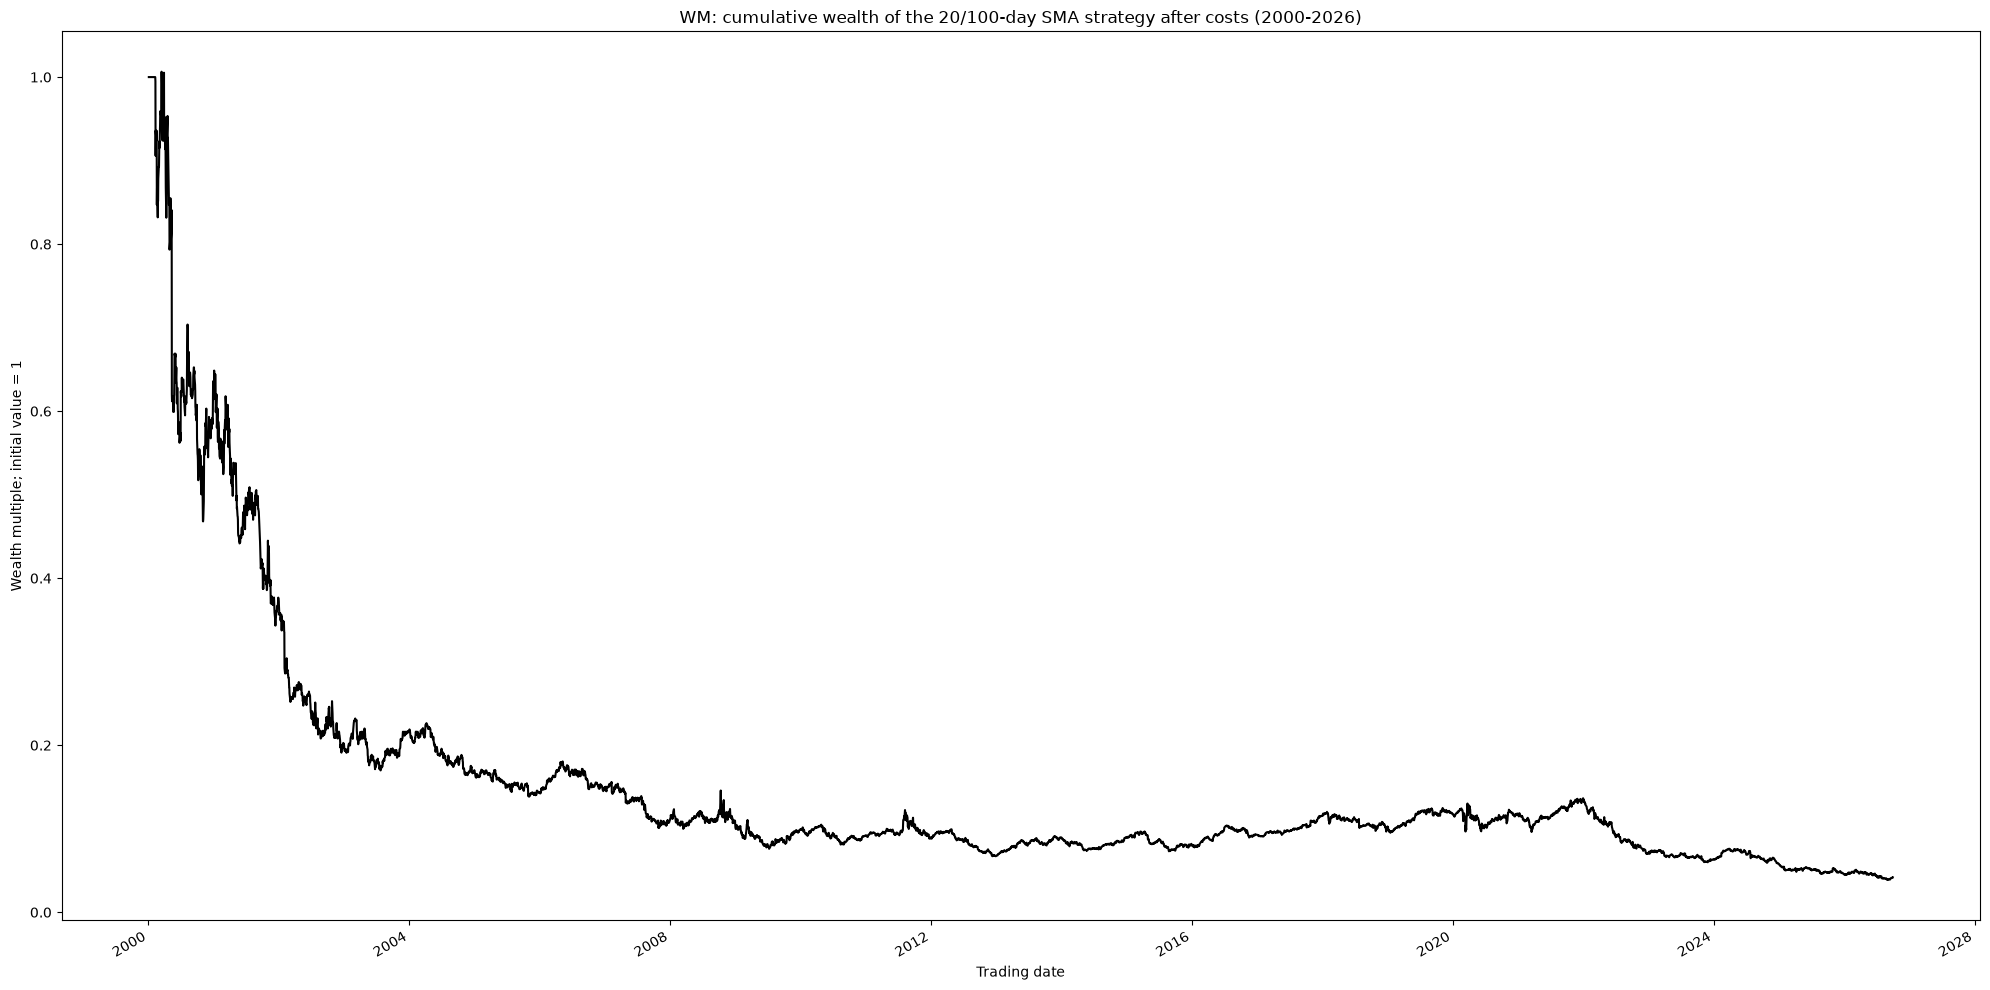

Final wealth multiple (2000-2026): 0.042


In [18]:
df['Returns'] = 1.0
print('Second-row Trade:', df.iloc[1]['Trade'])

# Cumulative wealth with the multiplicative-return formula above.
def computereturns(tdf, trate):
    prevrow = tdf.iloc[0]
    returncol = tdf.columns.get_loc('Returns')
    for i in range(len(tdf)):
        if i == 0:
            prev_i = i
        else:
            prevrow = tdf.iloc[prev_i]
            row = tdf.iloc[i]
            rt = (row['Close'] / prevrow['Close']) - 1
            t = prevrow['Returns'] * (1 + prevrow['Trade'] * rt) * (1 - trate * abs(row['Trade'] - prevrow['Trade']))
            tdf.iat[i, returncol] = t
            prev_i = i
    return tdf

df = computereturns(df, TRANSACTION_RATE)
plt.figure(figsize=(20, 10))
df['Returns'].plot(color='k', label='Returns')
plt.title('WM: cumulative wealth of the 20/100-day SMA strategy after costs (2000-2026)')
plt.xlabel('Trading date')
plt.ylabel('Wealth multiple; initial value = 1')
plt.tight_layout()
plt.show()
print(f"Final wealth multiple (2000-2026): {df['Returns'].iloc[-1]:.3f}")

`Returns` is a wealth multiple starting at 1: 1.2 means a cumulative gain of 20%, and values below 1 a loss. The transaction rate is $\delta = 0.5\%$; switching from +1 to −1, or back, is a change of 2 in the cost term. These results cover the full 2000–2026 history; the results of the same strategy on the test period (2021-09-23 to 2026-09-30) are reported in section 6.4.

## 3.2 Base Dataset: Inputs, Target and Folds

The forecasting task is to predict the next trading day's log return from the information available after the close of one trading day, and to convert it back to an adjusted closing price. Predicting returns rather than prices follows the time-delayed price-difference approach of Ang & Quek (2006): price levels are non-stationary, while daily returns are approximately stationary.

The base input set `base7` has seven inputs: the five most recent daily log returns, the 20-day volatility of daily log returns and the daily change in log volume. All models use the same inputs and folds.

In [19]:
# Only install the additional library if it is missing.
if importlib.util.find_spec('sklearn') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', 'scikit-learn>=1.5,<2'])

import sklearn
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

DATA_VERSION = 'wm_base_v1'
N_RETURN_LAGS = 5
VOLATILITY_WINDOW = 20
N_SPLITS = 5
VALIDATION_DAYS = 252
TEST_DAYS = 252
MODEL_SEEDS = [0, 1, 2, 3, 4]  # random seeds of the repeated model runs
MODEL_DATA_DIR = PROJECT_ROOT / 'data' / 'model_ready' / DATA_VERSION

FEATURE_NAMES = [f'return_lag_{lag}' for lag in range(1, N_RETURN_LAGS + 1)] + [
    'volatility_20', 'volume_log_change',
]
TARGET_NAME = 'target_log_return'

# The saved base dataset is built from the frozen snapshot only.
assert source_csv_hash == FROZEN_CSV_SHA256, (
    'The base dataset is built from the frozen WM CSV; a new Yahoo download may have different adjusted values.'
)
print('Data version:', DATA_VERSION)
print('Inputs:', FEATURE_NAMES)
print('Target:', TARGET_NAME, '(unscaled)')


Data version: wm_base_v1
Inputs: ['return_lag_1', 'return_lag_2', 'return_lag_3', 'return_lag_4', 'return_lag_5', 'volatility_20', 'volume_log_change']
Target: target_log_return (unscaled)


### 3.2.1 Inputs and target

Rows are indexed by the target date $t$, the day being predicted. Each row uses information up to the close of the previous trading day, $t-1$; dates are trading days.

| Column | Meaning |
|---|---|
| `return_lag_1` … `return_lag_5` | daily log returns on days $t-1$ … $t-5$ |
| `volatility_20` | sample standard deviation of the last 20 daily log returns, ending at $t-1$ |
| `volume_log_change` | $\log(V_{t-1} / V_{t-2})$, change in log volume |
| `target_log_return` | target: $\log(P_t / P_{t-1})$, $P$ = adjusted close |

A predicted log return is converted to a price forecast by $\hat P_t = P_{t-1} \exp(\hat r_t)$. The columns `forecast_date`, `price_at_forecast` and `target_price` align the results and give the price errors; they are not model inputs.

In [20]:
def make_model_samples(prices):
    """One row per target date; every feature is known by the previous close."""
    prices = prices.copy(deep=True)
    assert prices.index.is_unique and prices.index.is_monotonic_increasing
    assert not prices[['Close', 'Volume']].isna().any().any()
    assert (prices[['Close', 'Volume']] > 0).all().all()

    log_return = np.log(prices['Close'] / prices['Close'].shift(1))
    samples = pd.DataFrame(index=prices.index)
    samples.index.name = 'target_date'
    samples['forecast_date'] = pd.Series(prices.index, index=prices.index).shift(1)
    for lag in range(1, N_RETURN_LAGS + 1):
        samples[f'return_lag_{lag}'] = log_return.shift(lag)
    samples['volatility_20'] = log_return.rolling(
        VOLATILITY_WINDOW, min_periods=VOLATILITY_WINDOW,
    ).std(ddof=1).shift(1)
    samples['volume_log_change'] = np.log(
        prices['Volume'] / prices['Volume'].shift(1),
    ).shift(1)
    samples[TARGET_NAME] = log_return
    samples['price_at_forecast'] = prices['Close'].shift(1)
    samples['target_price'] = prices['Close']
    return samples

all_samples = make_model_samples(stock_df)
complete_rows = all_samples.notna().all(axis=1)
model_samples = all_samples.loc[complete_rows].copy()
excluded_dates = all_samples.index[~complete_rows]

# Only the 21 warm-up rows are incomplete.
assert complete_rows.iloc[-len(model_samples):].all()
assert len(excluded_dates) == VOLATILITY_WINDOW + 1
assert np.isfinite(model_samples.select_dtypes(include='number').to_numpy()).all()
assert (model_samples['forecast_date'] < model_samples.index).all()
np.testing.assert_allclose(
    model_samples['price_at_forecast'] * np.exp(model_samples[TARGET_NAME]),
    model_samples['target_price'], rtol=1e-12, atol=1e-12,
)

print(f'Source: {len(stock_df):,} days; warm-up excluded: {len(excluded_dates)}; usable: {len(model_samples):,} rows.')
print(f'{len(FEATURE_NAMES)} input columns + 1 target column; dates and prices are metadata.')
print('Target dates:', model_samples.index.min().date(), 'to', model_samples.index.max().date())
display(model_samples.head(3))
display(model_samples[FEATURE_NAMES + [TARGET_NAME]].describe().T)


Source: 6,726 days; warm-up excluded: 21; usable: 6,705 rows.
7 input columns + 1 target column; dates and prices are metadata.
Target dates: 2000-02-02 to 2026-09-30


,forecast_date,return_lag_1,return_lag_2,return_lag_3,return_lag_4,return_lag_5,volatility_20,volume_log_change,target_log_return,price_at_forecast,target_price
target_date,,,,,,,,,,,
2000-02-02,2000-02-01,0.000000,-0.010658,0.021430,0.044288,0.030653,0.020091,-0.520459,-0.007168,9.630919,9.562130
2000-02-03,2000-02-02,-0.007168,0.000000,-0.010658,0.021430,0.044288,0.020144,0.204195,0.042260,9.562130,9.974884
2000-02-04,2000-02-03,0.042260,-0.007168,0.000000,-0.010658,0.021430,0.022235,0.246430,-0.017392,9.974884,9.802904


,count,mean,std,min,25%,50%,75%,max
return_lag_1,6705.0,0.000458,0.015005,-0.137007,-0.006031,0.000614,0.006886,0.233094
return_lag_2,6705.0,0.000456,0.015006,-0.137007,-0.006038,0.000612,0.006886,0.233094
return_lag_3,6705.0,0.000459,0.015008,-0.137007,-0.006038,0.000614,0.006889,0.233094
return_lag_4,6705.0,0.000466,0.015018,-0.137007,-0.006038,0.000615,0.006891,0.233094
return_lag_5,6705.0,0.000471,0.015022,-0.137007,-0.006038,0.000616,0.006891,0.233094
volatility_20,6705.0,0.012999,0.007703,0.002429,0.008075,0.010852,0.015429,0.063735
volume_log_change,6705.0,-0.000151,0.380257,-2.004733,-0.232787,-0.010137,0.219261,2.359870
target_log_return,6705.0,0.000455,0.015007,-0.137007,-0.006038,0.000614,0.006886,0.233094


Only the first 21 rows, which lack the history needed for the 20-day volatility, are excluded. No other rows are removed, and no values are filled, clipped or transformed.

### 3.2.2 Five expanding-window folds

The data are split chronologically into five folds. Each fold has an expanding training set, followed by a 252-day validation block (about one trading year) and a 252-day test block. The validation block is used for hyperparameter selection and early stopping, and the test block only for evaluation. The five test blocks are consecutive and do not overlap; the test block of one fold becomes part of the history of the later folds, as in walk-forward evaluation.

Because each forecast is made after the previous close, the last training target may fall on the first validation forecast date (it is known at that close); no extra gap is needed between the blocks. Inputs are standardised with the mean and standard deviation of each fold's training rows only.

In [21]:
splitter = TimeSeriesSplit(n_splits=N_SPLITS, test_size=TEST_DAYS, gap=0)
folds = {}
fold_rows = []

for fold_id, (development_indices, test_indices) in enumerate(splitter.split(model_samples), start=1):
    assert len(development_indices) > VALIDATION_DAYS
    split_indices = {
        'train': development_indices[:-VALIDATION_DAYS],
        'val': development_indices[-VALIDATION_DAYS:],
        'test': test_indices,
    }
    split_frames = {name: model_samples.iloc[indices] for name, indices in split_indices.items()}
    train, val, test = (split_frames[name] for name in ['train', 'val', 'test'])
    assert train.index.max() < val.index.min() < test.index.min()
    assert val.index.max() < test.index.min()
    assert train.index.max() <= val['forecast_date'].iloc[0]
    assert val.index.max() <= test['forecast_date'].iloc[0]

    # Fit only on this fold's training inputs. Leave the target y unchanged.
    scaler = StandardScaler().fit(train[FEATURE_NAMES])
    arrays = {'feature_names': np.asarray(FEATURE_NAMES, dtype='U32')}
    row = {'fold': fold_id}
    for name, frame in split_frames.items():
        arrays[f'X_{name}'] = scaler.transform(frame[FEATURE_NAMES])
        arrays[f'y_{name}'] = frame[TARGET_NAME].to_numpy(copy=True)
        arrays[f'target_dates_{name}'] = frame.index.strftime('%Y-%m-%d').to_numpy(dtype='U10')
        arrays[f'forecast_dates_{name}'] = frame['forecast_date'].dt.strftime('%Y-%m-%d').to_numpy(dtype='U10')
        arrays[f'price_at_forecast_{name}'] = frame['price_at_forecast'].to_numpy(copy=True)
        arrays[f'target_price_{name}'] = frame['target_price'].to_numpy(copy=True)
        row.update({
            f'{name}_rows': len(frame),
            f'{name}_start': str(frame.index.min().date()),
            f'{name}_end': str(frame.index.max().date()),
        })
    np.testing.assert_allclose(arrays['X_train'].mean(axis=0), 0, atol=1e-12)
    np.testing.assert_allclose(arrays['X_train'].std(axis=0, ddof=0), 1, atol=1e-12)
    folds[fold_id] = {'arrays': arrays, 'scaler': scaler}
    fold_rows.append(row)

fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)
print('Standardization: (input - training mean) / training standard deviation, separately in each fold.')
print('The same fitted scaler transforms validation and test inputs; y is not standardized.')


,fold,train_rows,train_start,train_end,val_rows,val_start,val_end,test_rows,test_start,test_end
0,1,5193,2000-02-02,2020-09-22,252,2020-09-23,2021-09-22,252,2021-09-23,2022-09-22
1,2,5445,2000-02-02,2021-09-22,252,2021-09-23,2022-09-22,252,2022-09-23,2023-09-25
2,3,5697,2000-02-02,2022-09-22,252,2022-09-23,2023-09-25,252,2023-09-26,2024-09-25
3,4,5949,2000-02-02,2023-09-25,252,2023-09-26,2024-09-25,252,2024-09-26,2025-09-29
4,5,6201,2000-02-02,2024-09-25,252,2024-09-26,2025-09-29,252,2025-09-30,2026-09-30


Standardization: (input - training mean) / training standard deviation, separately in each fold.
The same fitted scaler transforms validation and test inputs; y is not standardized.


### 3.2.3 Target alignment and the naive forecast

The check below verifies that the true log return reconstructs the adjusted close, and computes the test error of the naive random-walk forecast, which predicts a zero log return (tomorrow's adjusted close equals today's). This naive forecast is the reference of section 6. Both the log-return RMSE and the adjusted-close RMSE are reported.

In [22]:
naive_rows = []
for fold_id, fold in folds.items():
    arrays = fold['arrays']
    true_return = arrays['y_test']
    current_price = arrays['price_at_forecast_test']
    true_price = arrays['target_price_test']
    np.testing.assert_allclose(current_price * np.exp(true_return), true_price, rtol=1e-12, atol=1e-12)
    naive_rows.append({
        'fold': fold_id,
        'test_rows': len(true_return),
        'naive_log_return_rmse': float(np.sqrt(np.mean(true_return ** 2))),
        'naive_adjusted_close_rmse_usd': float(np.sqrt(np.mean((current_price - true_price) ** 2))),
    })
naive_baseline = pd.DataFrame(naive_rows)
display(naive_baseline)
print('Price reconstruction and the zero-log-return / same-price naive check passed.')


,fold,test_rows,naive_log_return_rmse,naive_adjusted_close_rmse_usd
0,1,252,0.013124,1.925764
1,2,252,0.011130,1.685227
2,3,252,0.011466,2.159556
3,4,252,0.011433,2.483826
4,5,252,0.012784,2.830096


Price reconstruction and the zero-log-return / same-price naive check passed.


### 3.2.4 Saved base dataset

The base dataset is saved in `data/model_ready/wm_base_v1/`: `model_samples.csv` (unscaled inputs, target and date/price metadata), one NPZ file per fold with the standardised arrays, the fitted scalers (training-only means and scales) and a manifest with the settings and file hashes. Section 5 builds the arrays of every input set in the same way; for `base7` they are identical to these files.

In [23]:
MODEL_DATA_DIR.mkdir(parents=True, exist_ok=True)
model_samples.to_csv(MODEL_DATA_DIR / 'model_samples.csv', date_format='%Y-%m-%d')
fold_summary.to_csv(MODEL_DATA_DIR / 'fold_summary.csv', index=False)
naive_baseline.to_csv(MODEL_DATA_DIR / 'naive_baseline.csv', index=False)

for fold_id, fold in folds.items():
    np.savez_compressed(MODEL_DATA_DIR / f'fold_{fold_id:02d}.npz', **fold['arrays'])
    scaler = fold['scaler']
    training_dates = fold['arrays']['target_dates_train']
    scaler_info = {
        'type': 'StandardScaler', 'fit_split': 'train', 'feature_names': FEATURE_NAMES,
        'mean': scaler.mean_.tolist(), 'scale': scaler.scale_.tolist(), 'variance': scaler.var_.tolist(),
        'n_samples_seen': int(scaler.n_samples_seen_),
        'fit_target_date_start': str(training_dates[0]), 'fit_target_date_end': str(training_dates[-1]),
        'target_scaled': False,
    }
    (MODEL_DATA_DIR / f'fold_{fold_id:02d}_scaler.json').write_text(
        json.dumps(scaler_info, indent=2) + '\n', encoding='utf-8',
    )

feature_definitions = {
    **{f'return_lag_{lag}': f'log(P[t-{lag}] / P[t-{lag+1}])' for lag in range(1, N_RETURN_LAGS + 1)},
    'volatility_20': 'sample std (ddof=1) of 20 daily log returns ending at t-1',
    'volume_log_change': 'log(V[t-1] / V[t-2])',
}
manifest = {
    'data_version': DATA_VERSION, 'ticker': TICKER,
    'source_file': 'data/raw/' + RAW_NAME, 'source_csv_sha256': source_csv_hash,
    'source_rows': len(stock_df), 'source_start': str(stock_df.index.min().date()),
    'source_end': str(stock_df.index.max().date()),
    'price_basis': 'frozen adjusted close; stock_df.Close equals source_df.Adj Close',
    'forecast_origin': 'after close of the previous trading day',
    'index_meaning': 'target_date t; forecast_date is previous trading date t-1',
    'feature_names': FEATURE_NAMES, 'feature_definitions': feature_definitions,
    'target_name': TARGET_NAME, 'target_definition': 'log(P[t] / P[t-1])',
    'target_scaled': False, 'input_dtype': 'float64',
    'price_reconstruction': 'price_at_forecast * exp(predicted_log_return)',
    'usable_rows': len(model_samples), 'excluded_warmup_rows': len(excluded_dates),
    'target_start': str(model_samples.index.min().date()), 'target_end': str(model_samples.index.max().date()),
    'return_lags': N_RETURN_LAGS, 'volatility_window': VOLATILITY_WINDOW, 'volatility_ddof': 1,
    'n_splits': N_SPLITS, 'validation_days': VALIDATION_DAYS, 'test_days': TEST_DAYS,
    'gap': 0, 'shuffle': False, 'split_method': 'expanding training; trailing validation; consecutive outer tests',
    'scaler_fit': 'each fold training inputs only; sklearn StandardScaler (ddof=0)',
    'model_seeds_for_later_training': MODEL_SEEDS,
    'enhancement_datasets': [], 'models_trained': False,
    'runtime_versions': {**runtime_versions, 'scikit-learn': sklearn.__version__},
    'files': {},
}
for file_name in ['model_samples.csv', 'fold_summary.csv', 'naive_baseline.csv'] + [
    name for fold_id in folds for name in [f'fold_{fold_id:02d}.npz', f'fold_{fold_id:02d}_scaler.json']
]:
    file_path = MODEL_DATA_DIR / file_name
    manifest['files'][file_name] = {
        'sha256': hashlib.sha256(file_path.read_bytes()).hexdigest(), 'bytes': file_path.stat().st_size,
    }
(MODEL_DATA_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2) + '\n', encoding='utf-8')
print('Saved the base dataset to:', MODEL_DATA_DIR)


Saved the base dataset to: D:\6124\G31_project\data\model_ready\wm_base_v1


### 3.2.5 Loading the saved folds

The cell below reloads the saved files and checks that they equal the arrays computed above.

In [24]:
def load_fold(fold_id, folder=MODEL_DATA_DIR):
    """Arrays, dates, prices and scaler of one saved fold, checked against the hashes in the manifest."""
    manifest = json.loads((folder / 'manifest.json').read_text(encoding='utf-8'))
    array_path, scaler_path = folder / f'fold_{fold_id:02d}.npz', folder / f'fold_{fold_id:02d}_scaler.json'
    for path in (array_path, scaler_path):
        if hashlib.sha256(path.read_bytes()).hexdigest() != manifest['files'][path.name]['sha256']:
            raise ValueError(f'Saved data file changed: {path.name}')
    with np.load(array_path, allow_pickle=False) as saved:
        result = {name: saved[name].copy() for name in saved.files}
    result['scaler'] = json.loads(scaler_path.read_text(encoding='utf-8'))
    return result


training_data = {fold_id: load_fold(fold_id) for fold_id in range(1, N_SPLITS + 1)}
for fold_id, saved in training_data.items():
    for name, array in folds[fold_id]['arrays'].items():
        np.testing.assert_array_equal(saved[name], array)
display(pd.DataFrame([
    {'fold': fold_id, **{name: str(saved[name].shape) for name in ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']}}
    for fold_id, saved in training_data.items()
]))
print('The reloaded folds equal the arrays computed above.')

,fold,X_train,y_train,X_val,y_val,X_test,y_test
0,1,"(5193, 7)","(5193,)","(252, 7)","(252,)","(252, 7)","(252,)"
1,2,"(5445, 7)","(5445,)","(252, 7)","(252,)","(252, 7)","(252,)"
2,3,"(5697, 7)","(5697,)","(252, 7)","(252,)","(252, 7)","(252,)"
3,4,"(5949, 7)","(5949,)","(252, 7)","(252,)","(252, 7)","(252,)"
4,5,"(6201, 7)","(6201,)","(252, 7)","(252,)","(252, 7)","(252,)"


The reloaded folds equal the arrays computed above.


## 3.3 Additional Datasets

The seven `base7` inputs only use WM's own price and volume history, so they can test the weak form of market efficiency at most. We add two kinds of public information available at the close of each forecast day:

1. **Market, peer and implied-volatility data** from Yahoo Finance: the S&P 500 index (^GSPC), Republic Services (RSG, WM's closest listed peer in US waste management) and the CBOE Volatility Index (^VIX).
2. **World news events** from GDELT, the Global Database of Events, Language, and Tone (Leetaru & Schrodt, 2013).

The additional features are stored in a separate table, `model_inputs`, joined to the base dataset by target date.

### 3.3.1 S&P 500, RSG and VIX

The three daily series cover the same period as WM, January 2000 – September 2026, and are aligned to WM's trading days. All three trade on the same US calendar, so no value is forward-filled. Like the `base7` inputs, every feature for target date $t$ is computed from closes up to the forecast date $t-1$. The S&P 500, RSG and VIX close at the same time as WM (16:00 New York time), so they are known when the forecast is made.

| Feature | Definition (at forecast date $d = t-1$) | Motivation |
|---|---|---|
| `spx_r1` | $\ln(S_d / S_{d-1})$, S&P 500 log return | market-wide news reaching WM with a delay |
| `spx_r5` | $\ln(S_d / S_{d-5})$ | short-term market momentum or reversal |
| `spx_vol20` | standard deviation of the last 20 `spx_r1` | market risk regime |
| `rsg_r1` | $\ln(G_d / G_{d-1})$, RSG log return | industry-specific news |
| `rsg_r5` | $\ln(G_d / G_{d-5})$ | short-term industry momentum |
| `wm_rel5` | $\ln(P_d / P_{d-5}) - \ln(S_d / S_{d-5})$ | WM's performance relative to the market |
| `vix_log` | $\ln V_d$, log VIX close | expected 30-day market volatility (fear level) |
| `vix_chg` | $\ln(V_d / V_{d-1})$ | change in market fear |

Here $P$, $S$, $G$ and $V$ are the adjusted closes of WM, the S&P 500 and RSG, and the VIX close. The input set **`ext15`** consists of the seven `base7` inputs plus these eight features.

In [25]:
# 3.3.1  Load (or download) the S&P 500, RSG and VIX series and build the eight ext15 features.
EXTRA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'extra'
EXTRA_SYMBOLS = {'GSPC': '^GSPC', 'RSG': 'RSG', 'VIX': '^VIX'}


def load_extra_close(name):
    """Adjusted close of one additional series: the frozen CSV if present, otherwise a new Yahoo download."""
    path = EXTRA_DIR / f'{name}_{START_DATE}_{END_DATE_INCLUSIVE}_raw.csv'
    if path.is_file():
        frame = pd.read_csv(path, parse_dates=['Date'], index_col='Date')
        origin = 'frozen CSV'
    else:
        frame = yf.Ticker(EXTRA_SYMBOLS[name]).history(start=START_DATE, end=END_DATE_EXCLUSIVE, interval='1d',
                                                       auto_adjust=False, actions=False, raise_errors=True)
        frame.index = frame.index.tz_localize(None).normalize()
        frame.index.name = 'Date'
        EXTRA_DIR.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path)
        origin = 'new Yahoo download'
    print(f'{name:5s} {EXTRA_SYMBOLS[name]:6s} {len(frame):,} days, {frame.index.min().date()} to '
          f'{frame.index.max().date()} ({origin})')
    return frame['Adj Close'].astype(float)


wm_days = stock_df.index                                   # WM trading calendar
extra_close = {name: load_extra_close(name).reindex(wm_days) for name in EXTRA_SYMBOLS}
assert all(series.notna().all() for series in extra_close.values()), 'An additional series misses a WM trading day.'

log_wm, log_spx, log_rsg = np.log(stock_df['Close']), np.log(extra_close['GSPC']), np.log(extra_close['RSG'])
on_forecast_day = pd.DataFrame(index=wm_days)              # value known at the close of each day d
on_forecast_day['spx_r1'] = log_spx.diff()
on_forecast_day['spx_r5'] = log_spx - log_spx.shift(5)
on_forecast_day['spx_vol20'] = on_forecast_day['spx_r1'].rolling(20).std()
on_forecast_day['rsg_r1'] = log_rsg.diff()
on_forecast_day['rsg_r5'] = log_rsg - log_rsg.shift(5)
on_forecast_day['wm_rel5'] = (log_wm - log_wm.shift(5)) - on_forecast_day['spx_r5']
on_forecast_day['vix_log'] = np.log(extra_close['VIX'])
on_forecast_day['vix_chg'] = on_forecast_day['vix_log'].diff()
EXT8 = list(on_forecast_day.columns)

# Row t of model_inputs uses the values of its forecast date t-1, exactly like the base7 inputs.
ext_features = on_forecast_day.reindex(model_samples['forecast_date']).set_axis(model_samples.index)
assert ext_features.notna().all().all()
model_inputs = model_samples.join(ext_features)
print(f'\nmodel_inputs: {len(model_inputs):,} target dates; {len(EXT8)} ext features added, no missing values.')
display(ext_features.describe().T.round(4))

GSPC  ^GSPC  6,726 days, 2000-01-03 to 2026-09-30 (frozen CSV)
RSG   RSG    6,726 days, 2000-01-03 to 2026-09-30 (frozen CSV)
VIX   ^VIX   6,978 days, 2000-01-03 to 2026-09-30 (frozen CSV)

model_inputs: 6,705 target dates; 8 ext features added, no missing values.


,count,mean,std,min,25%,50%,75%,max
spx_r1,6705.0,0.0003,0.0121,-0.1277,-0.0047,0.0006,0.0059,0.1096
spx_r5,6705.0,0.0013,0.0247,-0.2026,-0.0100,0.0031,0.0145,0.1749
spx_vol20,6705.0,0.0102,0.0066,0.0021,0.0062,0.0086,0.0123,0.0617
rsg_r1,6705.0,0.0006,0.0154,-0.1423,-0.0060,0.0007,0.0076,0.1541
rsg_r5,6705.0,0.0028,0.0329,-0.2578,-0.0119,0.0039,0.0193,0.2612
wm_rel5,6705.0,0.0010,0.0288,-0.1835,-0.0127,0.0004,0.0146,0.2385
vix_log,6705.0,2.9169,0.3531,2.2127,2.6433,2.8741,3.1403,4.4151
vix_chg,6705.0,-0.0001,0.0717,-0.4424,-0.0399,-0.0056,0.0337,0.7682


### 3.3.2 GDELT world events

GDELT codes events reported in world news (who did what to whom, where and when) and records, for each event, the Goldstein scale of its potential impact (−10 conflict to +10 cooperation), the average tone of the articles mentioning it and the number of mentions. We query the GDELT 1.0 event table `gdelt-bq.full.events` in Google BigQuery. It covers our whole period: a separate coverage query gave 4.5 million events in 2000 rising to 73 million in 2016. The query aggregates the events of each calendar day into a few daily indicators, worldwide and for events located in the United States:

```sql
SELECT SQLDATE AS day,
       COUNT(*) AS n_all, SUM(NumMentions) AS mentions_all,
       AVG(GoldsteinScale) AS goldstein_all,
       SAFE_DIVIDE(SUM(AvgTone * NumMentions), SUM(NumMentions)) AS tone_all_w,
       AVG(IF(QuadClass = 4, 1, 0)) AS share_matconflict_all,
       AVG(IF(EventRootCode = '14', 1, 0)) AS share_protest_all,
       COUNTIF(ActionGeo_CountryCode = 'US') AS n_us,
       AVG(IF(ActionGeo_CountryCode = 'US', GoldsteinScale, NULL)) AS goldstein_us,
       SAFE_DIVIDE(SUM(IF(ActionGeo_CountryCode = 'US', AvgTone * NumMentions, 0)),
                   SUM(IF(ActionGeo_CountryCode = 'US', NumMentions, 0))) AS tone_us_w,
       AVG(IF(ActionGeo_CountryCode = 'US', IF(QuadClass IN (3, 4), 1, 0), NULL)) AS share_conflict_us,
       AVG(IF(ActionGeo_CountryCode = 'US', IF(EventRootCode = '14', 1, 0), NULL)) AS share_protest_us,
       AVG(IF(ActionGeo_CountryCode = 'US', IF(QuadClass = 4, 1, 0), NULL)) AS share_matconflict_us
FROM `gdelt-bq.full.events`
WHERE SQLDATE BETWEEN 19991101 AND 20260930
GROUP BY day ORDER BY day;
```

The result, one row per calendar day from 1999-11-01 to 2026-09-30, is saved as `data/gdelt/gdelt_daily_events.csv`. Running the query needs a Google account, so the notebook reads this file.

**Data quality.** GDELT's coverage and coding change over time. The number of events grows more than tenfold, and the average tone level breaks twice: in November 2012 (from about +5.6 to +2.7) and in February 2015 with the launch of GDELT 2.0 (from about +2.3 to −2.6), as the figure below shows. Raw levels and counts would therefore teach the model the history of GDELT rather than the news. We use seven indicators and transform each one into a **causal z-score against its own previous 60 calendar days**. The z-score is set to 0 for the 60 days after each break and clipped to ±4. Because GDELT dates are event dates and part of a day's news arrives after the US market close, the forecast for target date $t$ (made at the close of $d = t-1$) only uses GDELT values up to calendar day $d-1$. Weekend news thus reaches Monday's forecast.

| Feature | GDELT indicator (z-score) |
|---|---|
| `g_tone_us`, `g_tone_all` | mention-weighted average tone, US and worldwide |
| `g_gold_us` | average Goldstein scale, US |
| `g_conf_us` | share of conflict events (verbal or material), US |
| `g_protest_us` | share of protest events, US |
| `g_matconf_all` | share of material-conflict events, worldwide |
| `g_attention` | log of the number of mentions, worldwide (news volume) |

GDELT: 9,831 calendar days, 1999-11-01 to 2026-09-30


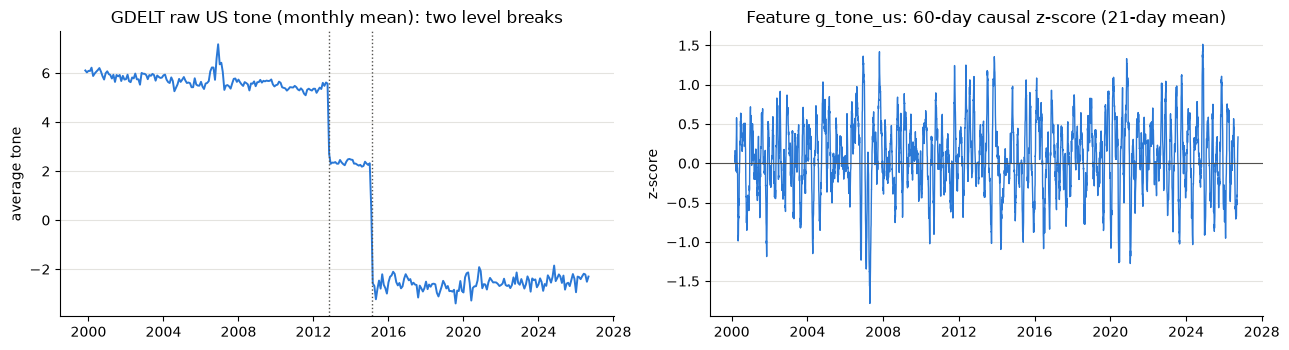

In [26]:
# 3.3.2  GDELT daily aggregates -> seven causal z-score features.
GDELT_CSV = PROJECT_ROOT / 'data' / 'gdelt' / 'gdelt_daily_events.csv'
GDELT_SOURCE = {'g_tone_us': 'tone_us_w', 'g_tone_all': 'tone_all_w', 'g_gold_us': 'goldstein_us',
                'g_conf_us': 'share_conflict_us', 'g_protest_us': 'share_protest_us',
                'g_matconf_all': 'share_matconflict_all', 'g_attention': 'mentions_all'}
GDELT_BREAKS = ['2012-11-01', '2015-02-18']            # tone-level breaks (see figure)
GDELT_WINDOW = 60                                      # calendar days
if not GDELT_CSV.is_file():
    raise FileNotFoundError(f'{GDELT_CSV} is missing: run the BigQuery query above and save its result there.')

gdelt = pd.read_csv(GDELT_CSV)
gdelt.index = pd.to_datetime(gdelt.pop('day').astype(str))
gdelt = gdelt.asfreq('D')
assert gdelt.notna().all().all(), 'GDELT has a missing calendar day.'
print(f'GDELT: {len(gdelt):,} calendar days, {gdelt.index.min().date()} to {gdelt.index.max().date()}')

z = pd.DataFrame(index=gdelt.index)
for name, column in GDELT_SOURCE.items():
    series = np.log(gdelt[column]) if column == 'mentions_all' else gdelt[column]
    previous = series.shift(1).rolling(GDELT_WINDOW, min_periods=GDELT_WINDOW)
    z[name] = ((series - previous.mean()) / previous.std()).clip(-4, 4)
for start in GDELT_BREAKS:
    z.loc[pd.Timestamp(start):pd.Timestamp(start) + pd.Timedelta(days=GDELT_WINDOW)] = 0.0
GDELT7 = list(z.columns)

# Target date t -> forecast date d = t-1 -> GDELT calendar day d-1.
gdelt_day = model_samples['forecast_date'] - pd.Timedelta(days=1)
gdelt_features = z.reindex(gdelt_day).set_axis(model_samples.index)
assert gdelt_features.notna().all().all()
model_inputs = model_inputs.join(gdelt_features)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
monthly = gdelt['tone_us_w'].resample('MS').mean()
axes[0].plot(monthly.index, monthly.values, lw=1.4, color='#2a78d6')
for start in GDELT_BREAKS:
    axes[0].axvline(pd.Timestamp(start), color='#52514e', ls=':', lw=1)
axes[0].set(title='GDELT raw US tone (monthly mean): two level breaks', ylabel='average tone')
smooth = gdelt_features['g_tone_us'].rolling(21).mean()
axes[1].plot(smooth.index, smooth.values, lw=1, color='#2a78d6')
axes[1].axhline(0, color='#52514e', lw=0.8)
axes[1].set(title='Feature g_tone_us: 60-day causal z-score (21-day mean)', ylabel='z-score')
for ax in axes:
    ax.grid(axis='y', color='#e4e3df'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

### 3.3.3 Input sets and a first look at the signal

The experiments use four input sets:

| Input set | Inputs | Used for |
|---|---|---|
| `base7` | the seven inputs of section 3.2 | baseline: WM's own price and volume history only |
| `ext15` | `base7` + the eight S&P 500 / RSG / VIX features | effect of additional market information |
| `base7_gdelt`, `ext15_gdelt` | the above + the seven GDELT features | effect of world-news information |

The table below gives the correlation of every input with the next-day log return and with its absolute value, on the training rows of the last fold (2000–2024). For the return, no input exceeds 0.04 in absolute value, so a single input explains at most about 0.15% of the variance. Section 6 tests whether non-linear combinations do better. The correlations with $|r|$ are larger for the volatility inputs (`volatility_20`, `spx_vol20`, `vix_log`), which motivates the volatility task of section 6.3.

In [27]:
# 3.3.3  Input sets and correlations on the training rows of fold 5.
FEATURE_SETS = {'base7': FEATURE_NAMES, 'ext15': FEATURE_NAMES + EXT8,
                'base7_gdelt': FEATURE_NAMES + GDELT7, 'ext15_gdelt': FEATURE_NAMES + EXT8 + GDELT7}
train_end = pd.Timestamp(fold_summary.set_index('fold').loc[N_SPLITS, 'train_end'])
train_rows = model_inputs.loc[:train_end]
correlations = pd.DataFrame({
    'corr. with next-day return': train_rows[FEATURE_SETS['ext15_gdelt']].corrwith(train_rows[TARGET_NAME]),
    'corr. with next-day |return|': train_rows[FEATURE_SETS['ext15_gdelt']].corrwith(train_rows[TARGET_NAME].abs()),
})
correlations.insert(0, 'group', ['base7'] * len(FEATURE_NAMES) + ['S&P 500 / RSG / VIX'] * len(EXT8)
                    + ['GDELT'] * len(GDELT7))
print(f'Training rows of fold {N_SPLITS}: {len(train_rows):,} ({train_rows.index.min().date()} to {train_end.date()})')
display(pd.DataFrame({name: len(cols) for name, cols in FEATURE_SETS.items()}, index=['number of inputs']))
display(correlations.round(4))

Training rows of fold 5: 6,201 (2000-02-02 to 2024-09-25)


,base7,ext15,base7_gdelt,ext15_gdelt
number of inputs,7,15,14,22


,group,corr. with next-day return,corr. with next-day |return|
return_lag_1,base7,-0.0345,-0.0744
return_lag_2,base7,-0.0388,-0.0598
return_lag_3,base7,-0.0168,-0.0655
return_lag_4,base7,-0.0153,-0.0219
return_lag_5,base7,-0.0059,-0.0109
volatility_20,base7,0.0125,0.3886
volume_log_change,base7,0.0258,0.0420
spx_r1,S&P 500 / RSG / VIX,-0.0250,-0.0923
spx_r5,S&P 500 / RSG / VIX,-0.0319,-0.1771
spx_vol20,S&P 500 / RSG / VIX,0.0003,0.3703


# 4. Methods

## 4.1 First-Order TSK Neuro-Fuzzy System

A first-order Takagi–Sugeno–Kang (TSK) fuzzy system (Takagi & Sugeno, 1985) with $R$ rules maps the standardised input vector $\mathbf{x} \in \mathbb{R}^D$ of section 3 to a forecast through rules of the form

$$\text{Rule } r: \ \text{IF } x_1 \text{ is } A_{r1} \text{ and } \dots \text{ and } x_D \text{ is } A_{rD}, \ \text{THEN } y_r(\mathbf{x}) = b_r + \mathbf{w}_r^\top \mathbf{x}.$$

Each antecedent fuzzy set is Gaussian, $\mu_{rd}(x_d) = \exp\!\big(-(x_d - c_{rd})^2 / (2\sigma_{rd}^2)\big)$, and the product t-norm gives the firing strength $f_r(\mathbf{x}) = \prod_{d} \mu_{rd}(x_d)$. The output is the average of the rule consequents weighted by the normalised firing strengths:

$$\hat{y}(\mathbf{x}) = \sum_{r=1}^{R} \bar{f}_r(\mathbf{x})\, y_r(\mathbf{x}), \qquad \bar{f}_r(\mathbf{x}) = \frac{f_r(\mathbf{x})}{\sum_{k=1}^{R} f_k(\mathbf{x})}.$$

The normalised firing strengths are computed as a softmax of the log firing strengths, which avoids numerical underflow, and each width is parameterised as $\sigma_{rd} = \operatorname{softplus}(s_{rd}) + 0.05$ so that it stays positive.

**Rule base.** A grid partition with three fuzzy sets per input would need $3^7 = 2{,}187$ rules for `base7` and $3^{15} \approx 1.4 \times 10^7$ for `ext15`. Instead, each rule is placed on a cluster of the training inputs: the centres $c_{rd}$ are the k-means centres (10 restarts) of the fold's training inputs, and every initial width equals the training standard deviation of its input (at least 0.2). The number of rules is $R \in \{2, 4, 8\}$. All consequent parameters start at zero.

**Training.** Centres, widths and consequents are trained jointly by gradient descent (Adam: Kingma & Ba, 2015; learning rate $10^{-3}$, mini-batches of 128), as in the mini-batch training of TSK systems of Wu et al. (2020). The model is therefore a hybrid neuro-fuzzy system: a fuzzy rule base whose parameters are learned like those of a neural network. The training objective is given in section 4.3.

In [28]:
import copy
import random

import torch
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_limits
from torch import nn
from torch.nn import functional as F


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


class TSK(nn.Module):
    """First-order TSK: Gaussian product antecedents, normalised firing strengths, linear consequents."""
    MIN_SIGMA = 0.05

    def __init__(self, n_features, n_rules, drop_rate=0.0):
        super().__init__()
        self.drop_rate, self.drop_generator = drop_rate, None
        self.centers = nn.Parameter(torch.zeros(n_rules, n_features))
        self.raw_scales = nn.Parameter(torch.zeros(n_rules, n_features))
        self.consequent_weights = nn.Parameter(torch.zeros(n_rules, n_features))
        self.consequent_bias = nn.Parameter(torch.zeros(n_rules))

    @property
    def sigmas(self):
        return F.softplus(self.raw_scales) + self.MIN_SIGMA

    @classmethod
    def from_training_data(cls, X, n_rules, seed, drop_rate=0.0):
        """k-means centres and training-SD widths; zero consequents."""
        X = np.asarray(X, dtype=np.float64)
        with threadpool_limits(limits=1):
            centers = KMeans(n_clusters=n_rules, n_init=10, random_state=seed).fit(X).cluster_centers_
        model = cls(X.shape[1], n_rules, drop_rate)
        widths = np.broadcast_to(np.maximum(X.std(axis=0), 0.2), centers.shape)
        with torch.no_grad():
            model.centers.copy_(torch.as_tensor(centers, dtype=torch.float32))
            model.raw_scales.copy_(torch.as_tensor(np.log(np.expm1(widths - cls.MIN_SIGMA)), dtype=torch.float32))
        return model

    def rule_weights(self, X, keep=None):
        """Normalised firing strengths; `keep` is a Boolean (samples, rules) DropRule mask (section 4.2)."""
        log_firing = -0.5 * ((X[:, None, :] - self.centers) / self.sigmas).square().sum(-1)
        if keep is None and self.training and self.drop_rate > 0:
            keep = torch.rand(log_firing.shape, generator=self.drop_generator) >= self.drop_rate
        if keep is not None:
            keep = keep | ~keep.any(-1, keepdim=True)            # a sample with every rule dropped keeps all
            log_firing = log_firing.masked_fill(~keep, -torch.inf)
        return torch.softmax(log_firing, -1)

    def forward(self, X, keep=None):
        rule_outputs = F.linear(X, self.consequent_weights, self.consequent_bias)
        return (self.rule_weights(X, keep) * rule_outputs).sum(-1)

## 4.2 DropRule and MC-DropRule

**DropRule** (Wu et al., 2020) is the fuzzy-system counterpart of dropout (Srivastava et al., 2014). During training, each rule is dropped independently with probability $p$ (the drop rate) for every training sample, and the output is the weighted average of the remaining rules, with the firing strengths renormalised over them. If all rules are dropped for a sample, all rules are kept. Each rule must then give a useful forecast on its own and not only in combination with the others, which regularises the rule base. All rules are used for the normal forecast.

**MC-DropRule.** Following Monte Carlo dropout (Gal & Ghahramani, 2016), we also keep DropRule active at prediction time, with the trained drop rate, and repeat the forward pass $M = 50$ times with independent masks. This gives two quantities for every forecast:

- the **MC mean** $m(\mathbf{x})$, an alternative point forecast (reported as *TSK + MC-DropRule*);
- the **MC standard deviation** $s(\mathbf{x})$, which measures how much the forecast depends on which rules are active, i.e. the disagreement between rules.

$s(\mathbf{x})$ is a measure of model uncertainty, not of the variability of returns. The ratio $|m(\mathbf{x})| / s(\mathbf{x})$ is used as a confidence score in the trading rule of section 4.5: a trade is made only when the forecast is large relative to the disagreement between rules.

In [29]:
def predict(model, X):
    """Forecast with all rules."""
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(np.asarray(X), dtype=torch.float32)).numpy().astype(np.float64)


def mc_predict(model, X, drop_rate, passes=50, seed=0):
    """MC-DropRule: mean and SD over `passes` forward passes with independent rule masks per sample."""
    rng = np.random.default_rng(seed)
    Xt = torch.as_tensor(np.asarray(X), dtype=torch.float32)
    n_rules = model.centers.shape[0]
    model.eval()
    with torch.no_grad():
        rule_outputs = F.linear(Xt, model.consequent_weights, model.consequent_bias)
        draws = np.stack([
            (model.rule_weights(Xt, torch.as_tensor(rng.random((len(Xt), n_rules)) >= drop_rate))
             * rule_outputs).sum(-1).numpy().astype(np.float64)
            for _ in range(passes)
        ])
    return draws.mean(0), draws.std(0)

## 4.3 Training Under a Low Signal-to-Noise Ratio

Daily returns contain little predictable structure. On the training rows of each fold, a linear least-squares regression on the inputs explains 0.4–0.5% (`base7`) to 0.9–1.1% (all 22 inputs) of the variance of the next-day return, and on the validation blocks it is worse than the training mean (pooled $R^2$ of −0.3% and −0.7%). A model fitted by least squares therefore fits mostly noise, and the more flexible the model, the more its forecasts vary beyond the predictable part of the return. The training is designed to keep the forecast close to the training mean unless the data support a departure from it, accepting a small bias for a large reduction in variance. Three choices serve this purpose.

1. **Standardised target.** The model is trained on $z = (y - \bar{y}_{\text{train}}) / s_{\text{train}}$, with the mean and SD of the fold's training targets, and its forecasts are transformed back. This keeps the learning rate of $10^{-3}$ in proportion to the size of the parameters and, because the consequents start at zero, makes the initial forecast equal to the training mean.
2. **Slope penalty** $\lambda_w \sum_r \lVert \mathbf{w}_r \rVert^2$ on the consequent slopes.
3. **Rule-bias shrinkage** $\lambda_b \sum_r (b_r - \bar{b})^2$, with $\bar{b}$ the mean of the rule biases. Even with flat consequents, rules with different biases make the forecast jump between rule regions. The penalty pulls the biases towards their common value without penalising that value. When both penalties are large, the model reduces to a constant forecast, the training mean; the selected penalties (section 5) set how far the forecast may move away from it.

The training loss is

$$L = \frac{1}{n}\sum_{i=1}^{n} \big(z_i - \hat{z}(\mathbf{x}_i)\big)^2 + \lambda_w \sum_{r} \lVert \mathbf{w}_r \rVert^2 + \lambda_b \sum_{r} (b_r - \bar{b})^2 .$$

**Epoch selection.** Training runs for at most 200 epochs. After each epoch, the RMSE on the fold's validation block is computed; the parameters of the best epoch are kept, and training stops after 25 epochs without improvement. The hyperparameters $R$, $\lambda_w$, $\lambda_b$ and $p$ are chosen on the validation blocks as described in section 5.

In [30]:
def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true, dtype=np.float64) - np.asarray(y_pred, dtype=np.float64)) ** 2)))


def fit_tsk(X_train, z_train, X_val, z_val, n_rules, l2_w, l2_b, drop_rate=0.0, seed=0,
            lr=1e-3, batch_size=128, max_epochs=200, patience=25, min_delta=1e-7):
    """Train on standardised targets z; return (model at the best validation epoch, best epoch)."""
    set_seed(seed)
    model = TSK.from_training_data(X_train, n_rules, seed, drop_rate)
    if drop_rate > 0:
        model.drop_generator = torch.Generator().manual_seed(seed + 100_003)
    tx = torch.as_tensor(np.asarray(X_train), dtype=torch.float32)
    tz = torch.as_tensor(np.asarray(z_train), dtype=torch.float32)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    batch_order = torch.Generator().manual_seed(seed)
    best, reference, best_state, best_epoch, stale = np.inf, np.inf, None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        order = torch.randperm(len(tx), generator=batch_order)
        for start in range(0, len(order), batch_size):
            i = order[start:start + batch_size]
            b = model.consequent_bias
            loss = (F.mse_loss(model(tx[i]), tz[i]) + l2_w * model.consequent_weights.square().sum()
                    + l2_b * (b - b.mean()).square().sum())
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        val_rmse = rmse(z_val, predict(model, X_val))
        if val_rmse < best:
            best, best_epoch, best_state = val_rmse, epoch, copy.deepcopy(model.state_dict())
        if val_rmse < reference - min_delta:
            reference, stale = val_rmse, 0
        else:
            stale += 1
        if stale >= patience:
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, best_epoch

## 4.4 Benchmark Models: MLP and LSTM

Two neural networks serve as benchmarks. They use the same inputs, folds, input standardisation, seeds and selection procedure as the TSK model (section 5); only the model and its training differ.

**MLP.** A feed-forward network with two hidden layers, ReLU activations, dropout after each hidden layer and a linear output: $D \to h_1 \to h_2 \to 1$, with $(h_1, h_2) \in \{(32, 16), (64, 32)\}$ and dropout $\in \{0, 0.2\}$.

**LSTM.** A single-layer LSTM (Hochreiter & Schmidhuber, 1997) reads a window of the last $L$ input rows, $\mathbf{x}_{t-L+1}, \dots, \mathbf{x}_t$, and a linear layer maps its last hidden state to the forecast, with $L \in \{5, 10, 20\}$ and hidden size $\in \{16, 32\}$. Because row $t$ only contains information up to day $t-1$, the window is known when the forecast is made. The windows of the first validation and test days use the last rows of the preceding block; the first $L-1$ training rows serve only as history.

**Training.** The target is divided by its training standard deviation (it is not centred), and the loss is the MSE. Both networks are trained full-batch with Adam, learning rate $\in \{10^{-3}, 3 \times 10^{-3}\}$ and weight decay $\in \{0, 10^{-3}\}$, for at most 300 epochs. The parameters of the epoch with the lowest validation loss are kept, and training stops after 20 epochs without improvement. The grids contain 16 MLP and 24 LSTM configurations.

In [31]:
MLP_GRID = {'hidden': ((32, 16), (64, 32)), 'dropout': (0.0, 0.2), 'weight_decay': (0.0, 1e-3), 'lr': (1e-3, 3e-3)}
LSTM_GRID = {'L': (5, 10, 20), 'hidden': (16, 32), 'weight_decay': (0.0, 1e-3), 'lr': (1e-3, 3e-3)}
NN_MAX_EPOCHS, NN_PATIENCE = 300, 20


class MLP(nn.Module):
    def __init__(self, n_features, hidden=(32, 16), dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden[0]), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden[1], 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class LSTM(nn.Module):
    def __init__(self, n_features, hidden):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden, num_layers=1, batch_first=True)
        self.output = nn.Linear(hidden, 1)

    def forward(self, x):
        steps, _ = self.lstm(x)
        return self.output(steps[:, -1]).squeeze(-1)


def make_sequences(X_prev, X_cur, y_cur, L):
    """Windows of L rows ending at each current row; the first windows reach back into X_prev."""
    history = np.concatenate((X_prev[-(L - 1):] if L > 1 else X_prev[:0], X_cur))
    return np.stack([history[i:i + L] for i in range(len(X_cur))]), y_cur


def make_lstm_fold(data, L):
    X_train, y_train = make_sequences(data['X_train'][:L - 1], data['X_train'][L - 1:], data['y_train'][L - 1:], L)
    X_val, y_val = make_sequences(data['X_train'], data['X_val'], data['y_val'], L)
    X_test, y_test = make_sequences(data['X_val'], data['X_test'], data['y_test'], L)
    return {**data, 'X_train': X_train, 'y_train': y_train, 'X_val': X_val, 'y_val': y_val,
            'X_test': X_test, 'y_test': y_test}


def nn_predict(model, X, y_std):
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X, dtype=torch.float32)).numpy() * y_std


def fit_nn(cfg, data, seed):
    """Full-batch Adam on y / SD(y_train); return (model at the best validation epoch, SD(y_train))."""
    set_seed(seed)
    y_std = float(np.std(data['y_train']))
    X_train = torch.as_tensor(data['X_train'], dtype=torch.float32)
    X_val = torch.as_tensor(data['X_val'], dtype=torch.float32)
    y_train = torch.as_tensor(data['y_train'] / y_std, dtype=torch.float32)
    y_val = torch.as_tensor(data['y_val'] / y_std, dtype=torch.float32)
    n_features = data['X_train'].shape[-1]
    model = (LSTM(n_features, cfg['hidden']) if cfg.get('model') == 'lstm'
             else MLP(n_features, cfg['hidden'], cfg['dropout']))
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    loss_fn = nn.MSELoss()
    best_loss, stale, best_state = float('inf'), 0, copy.deepcopy(model.state_dict())
    for _ in range(NN_MAX_EPOCHS):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(X_train), y_train)
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), y_val).item()
        if val_loss < best_loss:
            best_loss, stale, best_state = val_loss, 0, copy.deepcopy(model.state_dict())
        else:
            stale += 1
            if stale >= NN_PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, y_std

## 4.5 Trading Rules

**Portfolio formula.** All strategies use the formula of section 3.1.3. The position $F_t$ held over day $t$ is decided at the close of day $t-1$, and wealth evolves as

$$W_t = W_{t-1}\,(1 + F_t\, r_t)\,(1 - \delta\,\lvert F_t - F_{t-1} \rvert), \qquad \delta = 0.5\%,$$

with $r_t$ the simple return of the adjusted close. The five test blocks are chained into one 1,260-day period that starts in cash, and each position is carried over from one test block to the next. The performance measures are given in section 5.3.

**Without prediction.**
- *Buy-and-hold*: $F_t = 1$ on every day.
- *MA 20/100*: the moving-average crossover rule of section 3.1, long ($+1$) or short ($-1$).

**With prediction.** The forecast rules are long or flat ($F_t \in \{0, 1\}$):
- *dir_hold*, applied in the same way to every model: buy if $\hat{r}_t > c\,s$, sell if $\hat{r}_t < -c\,s$, otherwise keep the previous position; $s$ is the SD of the model's validation forecasts and $c \in \{0, 0.5, 1, 2, 4, 8\}$. With $c = 0$ the rule simply follows the sign of the forecast; a larger $c$ skips small forecasts.
- *mc_hold*, for TSK + MC-DropRule: buy if $m_t > 0$ and $m_t / s_t \ge k$, sell if $m_t < 0$ and $m_t / s_t \le -k$, otherwise keep the previous position. Here $m_t$ and $s_t$ are the MC-DropRule mean and SD (section 4.2) and $k \in \{0, 1, 2, 4, 8, 16\}$, so the rule trades only when the forecast is large relative to the disagreement between rules.

The threshold $c$ or $k$ is chosen for each fold and seed by the Sharpe ratio on the validation block (ties go to the lower turnover).

**Forecast-bottleneck-free framework.** Ang & Quek (2006) use a forecast in a different way: the trading rule is computed on the price series extended by the forecast close $\hat{P}_t = P_{t-1} \exp(\hat{r}_t)$, so that the forecast enters the moving averages as one more price. As a supplement, we apply this to the MA 20/100 rule in three variants: *ST-basic* (closes up to $t-1$, no forecast), *ST-model* (extended by a model's forecast) and *ST-ideal* (extended by the true close $P_t$). ST-ideal is the upper bound of what a perfect next-day forecast can add to the rule.

In [32]:
DELTA, ANN = 0.005, 252                    # transaction rate; trading days per year
C_GRID = (0.0, 0.5, 1.0, 2.0, 4.0, 8.0)    # dir_hold thresholds (multiples of the validation forecast SD)
K_GRID = (0.0, 1.0, 2.0, 4.0, 8.0, 16.0)   # mc_hold thresholds (MC mean / MC SD)


def wealth_path(F, r, delta=DELTA):
    """Daily returns of the portfolio formula and the turnover sum |F_t - F_{t-1}| (start in cash)."""
    F = np.asarray(F, float); prev = np.r_[0.0, F[:-1]]
    return (1 + F * np.asarray(r, float)) * (1 - delta * np.abs(F - prev)) - 1, float(np.abs(F - prev).sum())


def sharpe(daily):
    sd = np.std(daily, ddof=1)
    return float(np.mean(daily) / sd * np.sqrt(ANN)) if sd > 0 else 0.0


def portfolio_stats(daily):
    w = np.cumprod(1 + np.asarray(daily))
    return {'final_wealth': w[-1], 'ann_return_%': 100 * (w[-1] ** (ANN / len(w)) - 1), 'sharpe': sharpe(daily),
            'max_drawdown_%': 100 * float((w / np.maximum.accumulate(np.r_[1.0, w])[1:] - 1).min())}


# ---- without prediction
def ma_positions(close, fast, slow):
    """MA crossover rule (section 3.1): +1 / -1 from the last crossover, 0 before the first one."""
    f, s = close.rolling(fast, min_periods=1).mean(), close.rolling(slow, min_periods=1).mean()
    return (f > s).astype(float).diff().fillna(0.0).replace(0.0, np.nan).ffill().fillna(0.0)


# ---- with prediction (long / flat)
def hold_by_size(pred, s, c, start=0.0):
    """dir_hold: buy above +c*s, sell below -c*s, otherwise keep the position."""
    F, cur = np.empty(len(pred)), start
    for i, x in enumerate(pred):
        cur = 1.0 if x > c * s else 0.0 if x < -c * s else cur
        F[i] = cur
    return F


def hold_by_confidence(mean, ratio, k, start=0.0):
    """mc_hold: buy if mean > 0 and mean/SD >= k, sell if mean < 0 and mean/SD <= -k, otherwise keep."""
    F, cur = np.empty(len(mean)), start
    for i, (m, q) in enumerate(zip(mean, ratio)):
        cur = 1.0 if (m > 0 and q >= k) else 0.0 if (m < 0 and q <= -k) else cur
        F[i] = cur
    return F


def best_on_validation(make_positions, grid, r_val):
    """Grid value with the highest validation Sharpe (ties: lower turnover); a rule that never invests scores -inf."""
    scored = []
    for g in grid:
        F = make_positions(g)
        daily, turnover = wealth_path(F, r_val)
        scored.append((sharpe(daily) if F.any() else -np.inf, -turnover, g))
    return max(scored)[2]


# ---- forecast-bottleneck-free framework (Ang & Quek, 2006)
def extended_ma_positions(close, d_prev, ext=None, fast=20, slow=100):
    """MA crossover rule decided at the closes d_prev; `ext` extends each series by one close for the next day."""
    if ext is None:                                                           # ST-basic
        f, s = (close.rolling(w).mean().loc[d_prev].values for w in (fast, slow))
    else:                                                                     # ST-model / ST-ideal
        f, s = ((close.rolling(w - 1).sum().loc[d_prev].values + ext) / w for w in (fast, slow))
    return np.where(f > s, 1.0, -1.0)

# 5. Experimental Protocol

## 5.1 Evaluation Design

**Tasks.** Two forecasting tasks use the same inputs, folds and models: the next-day log return $r_t$ (sections 6.1 and 6.2) and the next-day absolute log return $\lvert r_t \rvert$, a simple measure of daily volatility (section 6.3). The return task is run with the four input sets of section 3.3.3, the volatility task with `base7` and `ext15`.

**Folds.** All models use the five expanding-window folds of section 3.2.2, whose test blocks cover 2021-09-23 to 2026-09-30 (1,260 trading days): each model is trained on the training rows, its training epoch is chosen on the validation block, and it is not refitted on the validation data.

**Reference forecasts.** For the return task, the zero return (the random walk: tomorrow's adjusted close equals today's) and the mean return of the training rows. For the volatility task, the training mean of $\lvert r \rvert$, the RiskMetrics EWMA volatility ($\lambda = 0.94$; J.P. Morgan/Reuters, 1996) and the 20-day historical volatility; the last two estimate the SD of the return and are multiplied by $\sqrt{2/\pi}$, the ratio $\mathbb{E}\lvert r \rvert / \sigma$ for a normal return.

In [33]:
# Fold arrays for any input set and task, and the reference forecasts.
TASKS = {'return': ['base7', 'ext15', 'base7_gdelt', 'ext15_gdelt'], 'vol': ['base7', 'ext15']}
SEEDS, SELECTION_SEEDS, FOLD_IDS = (0, 1, 2, 3, 4), (0, 1, 2), list(range(1, N_SPLITS + 1))
fold_bounds = fold_summary.set_index('fold')


def fold_arrays(k, features, task):
    """Inputs standardised with fold k's training rows; y = log return or |log return|; z = standardised y."""
    b = fold_bounds.loc[k]
    rows = {'train': model_inputs.loc[:b.train_end], 'val': model_inputs.loc[b.val_start:b.val_end],
            'test': model_inputs.loc[b.test_start:b.test_end]}
    cols = FEATURE_SETS[features]
    mu, sd = rows['train'][cols].mean(), rows['train'][cols].std(ddof=0).replace(0, 1)
    d = {}
    for part, frame in rows.items():
        y = frame[TARGET_NAME].to_numpy(copy=True)
        d[f'X_{part}'] = ((frame[cols] - mu) / sd).to_numpy(dtype=float, copy=True)
        d[f'y_{part}'] = np.abs(y) if task == 'vol' else y
        d[f'dates_{part}'] = frame.index.strftime('%Y-%m-%d').to_numpy()
    d['y_mean'], d['y_sd'] = d['y_train'].mean(), d['y_train'].std()
    for part in ('train', 'val', 'test'):
        d[f'z_{part}'] = (d[f'y_{part}'] - d['y_mean']) / d['y_sd']
    return d


# RiskMetrics EWMA variance of the daily log return through each close (initialised with the first 20 returns).
log_r = np.log(stock_df['Close']).diff().to_numpy()
ewma_var = np.full(len(log_r), np.nan)
ewma_var[20] = np.nanvar(log_r[1:21])
for i in range(21, len(log_r)):
    ewma_var[i] = 0.94 * ewma_var[i - 1] + 0.06 * log_r[i] ** 2
ewma_sigma = pd.Series(np.sqrt(ewma_var), index=stock_df.index)


def prediction_frame(model, k, seed, part, d, y_pred, mc_std=None):
    out = pd.DataFrame({'model': model, 'fold': k, 'seed': seed, 'part': part, 'target_date': d[f'dates_{part}'],
                        'y_true': d[f'y_{part}'], 'y_pred': y_pred})
    if mc_std is not None:
        out['mc_std'] = mc_std
    return out


def reference_forecasts(task, folds):
    """Reference forecasts of section 5.1 (seed = -1: no randomness)."""
    out = []
    for k, d in folds.items():
        for part in ('val', 'test'):
            dates = pd.DatetimeIndex(d[f'dates_{part}'])
            n = len(dates)
            refs = {'training_mean': np.full(n, d['y_train'].mean())}
            if task == 'return':
                refs['zero_return'] = np.zeros(n)
            else:
                g = np.sqrt(2 / np.pi)
                refs['ewma'] = g * ewma_sigma.reindex(model_inputs.loc[dates, 'forecast_date']).to_numpy()
                refs['hist_vol20'] = g * model_inputs.loc[dates, 'volatility_20'].to_numpy()
            out += [prediction_frame(name, k, -1, part, d, p) for name, p in refs.items()]
    return pd.concat(out, ignore_index=True)

## 5.2 Hyperparameter Selection

Hyperparameters are chosen by grid search on validation data. One 252-day validation block is a short sample for returns this noisy, so the choice for fold $k$ uses all validation blocks that end before its test block: every configuration is trained on the training rows of fold $j$ and scored on the validation block of fold $j$, for $j = 1, \dots, k$, with seeds 0–2. The selection score is the RMSE pooled over these blocks (squared errors averaged over the seeds of a block, then over the blocks), and the configuration with the lowest score is used for fold $k$.

- **TSK**, in two steps. First, $R \in \{2, 4, 8\}$, $\lambda_w \in \{0.03, 0.3, 3\}$ and $\lambda_b \in \{0, 0.03, 0.3, 3, 10, 30\}$ (54 configurations) are searched without DropRule, which gives *TSK*. Then the drop rate $p \in \{0.1, 0.2, 0.3\}$ is chosen at the selected $(R, \lambda_w, \lambda_b)$, which gives *TSK + DropRule*. *TSK + MC-DropRule* uses the same trained models with MC-DropRule prediction.
- **MLP and LSTM**: the grids of section 4.4 (16 and 24 configurations).

The search is repeated for every input set and task. It takes about 1–2 hours on 16 CPU cores, so its results are saved in `cache/search/`, which is included in the project repository, and reloaded by default; setting `RUN_SEARCH = True` repeats it. The configurations selected for each fold are listed at the start of section 6. The thresholds of the forecast-based trading rules are chosen on each fold's validation block (section 4.5).

In [34]:
import warnings
from itertools import product

from joblib import Parallel, delayed

TSK_GRID = [dict(n_rules=r, l2_w=w, l2_b=b) for r, w, b in product((2, 4, 8), (0.03, 0.3, 3.0), (0.0, 0.03, 0.3, 3.0, 10.0, 30.0))]
DROP_RATES = (0.1, 0.2, 0.3)
NN_CONFIGS = {'mlp': [dict(hidden=h, dropout=p, weight_decay=w, lr=lr) for h, p, w, lr in product(*MLP_GRID.values())],
              'lstm': [dict(model='lstm', L=L, hidden=h, weight_decay=w, lr=lr) for L, h, w, lr in product(*LSTM_GRID.values())]}
SEARCH_DIR = PROJECT_ROOT / 'cache' / 'search'
config_key = lambda cfg: json.dumps(cfg, sort_keys=True)


def tsk_val_mse(d, cfg, seed):
    torch.set_num_threads(1)
    model, _ = fit_tsk(d['X_train'], d['z_train'], d['X_val'], d['z_val'], seed=seed, **cfg)
    return float(np.mean((d['y_val'] - (d['y_mean'] + d['y_sd'] * predict(model, d['X_val']))) ** 2))


def nn_fit(d, cfg, seed):
    torch.set_num_threads(1)
    data = make_lstm_fold(d, cfg['L']) if cfg.get('model') == 'lstm' else d
    model, y_std = fit_nn(cfg, data, seed)
    return data, model, y_std


def nn_val_mse(d, cfg, seed):
    data, model, y_std = nn_fit(d, cfg, seed)
    return float(np.mean((data['y_val'] - nn_predict(model, data['X_val'], y_std)) ** 2))


def pooled_choice(runs, k, candidates=None):
    """Configuration with the lowest pooled validation RMSE over the blocks of folds 1..k."""
    r = runs[runs.fold <= k] if candidates is None else runs[(runs.fold <= k) & runs.config.isin(candidates)]
    block = r.groupby(['config', 'fold']).val_mse.mean().reset_index()
    complete = block.groupby('config').fold.nunique() == k
    return block.groupby('config').val_mse.mean()[complete].idxmin()


def search(task, features):
    """Grid search with the pooled rule; returns (validation runs, selected configuration per model and fold)."""
    folds = {k: fold_arrays(k, features, task) for k in FOLD_IDS}
    parallel = Parallel(n_jobs=N_JOBS)

    def validate(model, fn, configs, blocks):
        jobs = [(c, j, s) for c in configs for j in blocks for s in SELECTION_SEEDS]
        mse = parallel(delayed(fn)(folds[j], c, s) for c, j, s in jobs)
        return pd.DataFrame({'model': model, 'config': [config_key(c) for c, _, _ in jobs],
                             'fold': [j for _, j, _ in jobs], 'seed': [s for _, _, s in jobs], 'val_mse': mse})

    runs = validate('tsk', tsk_val_mse, [dict(c, drop_rate=0.0) for c in TSK_GRID], FOLD_IDS)
    chosen = {('tsk', k): pooled_choice(runs, k) for k in FOLD_IDS}
    need = {config_key(dict(json.loads(chosen[('tsk', k)]), drop_rate=p)): k for k in FOLD_IDS for p in DROP_RATES}
    dr_runs = pd.concat([validate('tsk_dr', tsk_val_mse, [json.loads(c)], range(1, k + 1)) for c, k in need.items()])
    for k in FOLD_IDS:
        cands = [config_key(dict(json.loads(chosen[('tsk', k)]), drop_rate=p)) for p in DROP_RATES]
        chosen[('tsk_dr', k)] = pooled_choice(dr_runs, k, cands)
    runs = pd.concat([runs, dr_runs])
    for name, configs in NN_CONFIGS.items():
        r = validate(name, nn_val_mse, configs, FOLD_IDS)
        runs = pd.concat([runs, r])
        chosen.update({(name, k): pooled_choice(r, k) for k in FOLD_IDS})
    choices = pd.DataFrame([{'model': m, 'fold': k, 'config': c} for (m, k), c in chosen.items()])
    return runs.reset_index(drop=True), choices


def selected_configurations(task, features):
    """Saved search results, or a new search if RUN_SEARCH is True or nothing is saved."""
    folder = SEARCH_DIR / f'{task}_{features}'
    paths = (folder / 'validation_runs.csv.gz', folder / 'choices.csv')
    if RUN_SEARCH or not all(p.is_file() for p in paths):
        folder.mkdir(parents=True, exist_ok=True)
        runs, choices = search(task, features)
        runs.to_csv(paths[0], index=False, compression='gzip'); choices.to_csv(paths[1], index=False)
    return pd.read_csv(paths[0]), pd.read_csv(paths[1])


def short(cfg):
    c = json.loads(cfg)
    if 'n_rules' in c:
        return f"R={c['n_rules']}, λw={c['l2_w']:g}, λb={c['l2_b']:g}" + (f", p={c['drop_rate']:g}" if c['drop_rate'] else '')
    head = f"L={c['L']}, h={c['hidden']}" if 'L' in c else f"h={tuple(c['hidden'])}, drop={c['dropout']:g}"
    return f"{head}, wd={c['weight_decay']:g}, lr={c['lr']:g}"


# ---- final models (trained at the start of section 6)
MC_PASSES = 50


def final_tsk(d, k, name, cfg, seed):
    torch.set_num_threads(1)
    model, _ = fit_tsk(d['X_train'], d['z_train'], d['X_val'], d['z_val'], seed=seed, **cfg)
    out = []
    for part in ('val', 'test'):
        X = d[f'X_{part}']
        out.append(prediction_frame(name, k, seed, part, d, d['y_mean'] + d['y_sd'] * predict(model, X)))
        if cfg['drop_rate'] > 0:
            mean, sd = mc_predict(model, X, cfg['drop_rate'], MC_PASSES, seed=10_000 * k + seed)
            out.append(prediction_frame('tsk_mc', k, seed, part, d, d['y_mean'] + d['y_sd'] * mean, d['y_sd'] * sd))
    return pd.concat(out)


def final_nn(d, k, name, cfg, seed):
    data, model, y_std = nn_fit(d, cfg, seed)
    return pd.concat([prediction_frame(name, k, seed, part, d, nn_predict(model, data[f'X_{part}'], y_std))
                      for part in ('val', 'test')])


def final_predictions(task, features, choices):
    """Validation and test forecasts of the selected models (seeds 0-4) and of the reference forecasts."""
    folds = {k: fold_arrays(k, features, task) for k in FOLD_IDS}
    jobs = [(final_tsk if row.model.startswith('tsk') else final_nn, row.fold, row.model, json.loads(row.config), s)
            for row in choices.itertuples() for s in SEEDS]
    with warnings.catch_warnings():                 # idle loky workers time out between experiments; harmless
        warnings.filterwarnings('ignore', message='A worker stopped while some jobs were given to the executor')
        preds = Parallel(n_jobs=N_JOBS)(delayed(fn)(folds[k], k, m, cfg, s) for fn, k, m, cfg, s in jobs)
    return pd.concat(preds + [reference_forecasts(task, folds)], ignore_index=True)

## 5.3 Metrics and Tests

**Forecast accuracy.** On each fold's test block and for each seed we compute:
- the RMSE of the log return (the main measure); for the volatility task, the RMSE and the mean absolute error of $\lvert r \rvert$;
- the price RMSE ratio: the RMSE of the reconstructed adjusted close $\hat{P}_t = P_{t-1} \exp(\hat{r}_t)$ divided by that of the random walk;
- the directional accuracy: the share of days on which the forecast and the actual return have the same sign.

Each metric is averaged over the five seeds of a fold and reported as the mean (± SD) over the five folds.

**Significance.** Two forecasts are compared with the Diebold–Mariano (DM) test (Diebold & Mariano, 1995) on the daily squared errors of all 1,260 test days, each averaged over the seeds, using a Newey–West variance (Newey & West, 1987) with 10 lags and a two-sided p-value.

**Trading.** Each strategy is evaluated on the chained test period by its final wealth $W$ (starting from 1), the annualised Sharpe ratio $\sqrt{252}\,\bar{x}/s_x$ of its daily returns $x_t$ (risk-free rate 0), its maximum drawdown and its turnover $\sum_t \lvert F_t - F_{t-1} \rvert$. Strategies that depend on a seed are reported as the mean over seeds. The difference in Sharpe ratio from buy-and-hold is given with a 95% interval from a circular block bootstrap (blocks of 20 days, 2,000 resamples) of the seed-averaged daily returns.

In [35]:
from math import erfc


def return_metrics(g):
    """Log-return RMSE, directional accuracy and price RMSE relative to the random walk (one fold and seed)."""
    y, p = g.y_true.to_numpy(), g.y_pred.to_numpy()
    price = model_inputs.loc[pd.DatetimeIndex(g.target_date), 'price_at_forecast'].to_numpy()
    true_price = price * np.exp(y)
    return {'rmse': rmse(y, p), 'dir_acc': float(np.mean(np.sign(p) == np.sign(y))),
            'price_ratio': rmse(true_price, price * np.exp(p)) / rmse(true_price, price)}


def vol_metrics(g):
    return {'rmse': rmse(g.y_true, g.y_pred), 'mae': float(np.mean(np.abs(g.y_true - g.y_pred)))}


def summary_table(preds, metric_fn, labels):
    """Metric per fold and seed -> mean over seeds -> mean and SD over the five folds."""
    test = preds[(preds.part == 'test') & preds.model.isin(labels)]
    runs = pd.DataFrame([{'model': m, 'fold': k, **metric_fn(g)} for (m, k, s), g in test.groupby(['model', 'fold', 'seed'])])
    table = runs.groupby(['model', 'fold']).mean().groupby('model').agg(['mean', 'std'])
    table.columns = [f'{metric} ({stat})' if stat == 'std' else metric for metric, stat in table.columns]
    return table.rename(index=labels).sort_values('rmse')


def daily_loss(preds, model):
    """Seed-averaged squared error on each test day."""
    g = preds[(preds.part == 'test') & (preds.model == model)]
    return ((g.y_true - g.y_pred) ** 2).groupby(g.target_date).mean().sort_index()


def dm_test(loss_a, loss_b, lag=10):
    """Diebold-Mariano test of equal accuracy (Newey-West variance); t < 0 means a is more accurate."""
    d = np.asarray(loss_a, float) - np.asarray(loss_b, float)
    n, u = len(d), d - d.mean()
    s = u @ u / n + 2 * sum((1 - j / (lag + 1)) * (u[j:] @ u[:-j] / n) for j in range(1, lag + 1))
    t = d.mean() / np.sqrt(s / n)
    return float(t), float(erfc(abs(t) / np.sqrt(2)))


def sharpe_difference_ci(a, b, block=20, reps=2000, seed=0):
    """95% circular block-bootstrap interval of Sharpe(a) - Sharpe(b) for two daily return series."""
    rng, n = np.random.default_rng(seed), len(a)
    diffs = []
    for _ in range(reps):
        idx = (rng.integers(0, n, int(np.ceil(n / block)))[:, None] + np.arange(block)).ravel()[:n] % n
        diffs.append(sharpe(a[idx]) - sharpe(b[idx]))
    return tuple(np.percentile(diffs, [2.5, 97.5]))

# 6. Results

All results in this section come from the models selected as described in section 5.2. The first cell below reloads the saved search results (or repeats the search if `RUN_SEARCH = True`) and lists the configuration selected for each fold. The second cell trains each selected configuration on its fold's training rows with seeds 0–4, which change the initialisation (the k-means centres of TSK, the network weights of MLP and LSTM), the mini-batch order and the DropRule masks. MC-DropRule uses the TSK + DropRule models with 50 passes. The test forecasts are evaluated in sections 6.1–6.3, and the validation forecasts set the thresholds of the trading rules in section 6.4.

In [36]:
MODEL_LABELS = {'tsk': 'TSK', 'tsk_dr': 'TSK + DropRule', 'mlp': 'MLP', 'lstm': 'LSTM'}
search_results = {(task, f): selected_configurations(task, f) for task, sets in TASKS.items() for f in sets}
selected = pd.concat([ch.assign(task=task, inputs=f) for (task, f), (_, ch) in search_results.items()])
selected['config'] = selected.config.map(short)
selected['model'] = selected.model.map(MODEL_LABELS)
display(selected.pivot_table(index=['task', 'inputs', 'model'], columns='fold', values='config', aggfunc='first', sort=False)
        .add_prefix('fold '))

fold                                                                 fold 1  \
task   inputs      model                                                      
return base7       TSK                                     R=8, λw=3, λb=30   
                   TSK + DropRule                   R=8, λw=3, λb=30, p=0.3   
                   MLP             h=(64, 32), drop=0.2, wd=0.001, lr=0.003   
                   LSTM                          L=10, h=16, wd=0, lr=0.003   
       ext15       TSK                                   R=8, λw=0.3, λb=10   
                   TSK + DropRule                 R=8, λw=0.3, λb=10, p=0.2   
                   MLP               h=(64, 32), drop=0, wd=0.001, lr=0.003   
                   LSTM                           L=5, h=16, wd=0, lr=0.003   
       base7_gdelt TSK                                    R=4, λw=0.3, λb=0   
                   TSK + DropRule                  R=4, λw=0.3, λb=0, p=0.2   
                   MLP             h=(32, 16), drop=0.2, wd=0.001, lr=0.003   
                   LSTM                       L=5, h=32, wd=0.001, lr=0.003   
       ext15_gdelt TSK                                   R=4, λw=3, λb=0.03   
                   TSK + DropRule                 R=4, λw=3, λb=0.03, p=0.1   
                   MLP             h=(64, 32), drop=0.2, wd=0.001, lr=0.003   
                   LSTM                       L=5, h=32, wd=0.001, lr=0.003   
vol    base7       TSK                                    R=8, λw=0.3, λb=0   
                   TSK + DropRule                  R=8, λw=0.3, λb=0, p=0.1   
                   MLP                   h=(32, 16), drop=0, wd=0, lr=0.001   
                   LSTM                       L=5, h=32, wd=0.001, lr=0.003   
       ext15       TSK                                    R=8, λw=0.3, λb=0   
                   TSK + DropRule                  R=8, λw=0.3, λb=0, p=0.1   
                   MLP             h=(64, 32), drop=0.2, wd=0.001, lr=0.003   
                   LSTM                      L=10, h=32, wd=0.001, lr=0.003   

fold                                                                 fold 2  \
task   inputs      model                                                      
return base7       TSK                                   R=4, λw=0.3, λb=30   
                   TSK + DropRule                 R=4, λw=0.3, λb=30, p=0.1   
                   MLP             h=(64, 32), drop=0.2, wd=0.001, lr=0.003   
                   LSTM                      L=20, h=16, wd=0.001, lr=0.003   
       ext15       TSK                                   R=4, λw=0.03, λb=0   
                   TSK + DropRule                 R=4, λw=0.03, λb=0, p=0.3   
                   MLP             h=(64, 32), drop=0.2, wd=0.001, lr=0.003   
                   LSTM                      L=10, h=16, wd=0.001, lr=0.003   
       base7_gdelt TSK                                   R=8, λw=0.3, λb=30   
                   TSK + DropRule                 R=8, λw=0.3, λb=30, p=0.2   
                   MLP                 h=(64, 32), drop=0.2, wd=0, lr=0.003   
                   LSTM                          L=20, h=16, wd=0, lr=0.003   
       ext15_gdelt TSK                                 R=4, λw=0.3, λb=0.03   
                   TSK + DropRule               R=4, λw=0.3, λb=0.03, p=0.1   
                   MLP             h=(64, 32), drop=0.2, wd=0.001, lr=0.003   
                   LSTM                       L=5, h=32, wd=0.001, lr=0.003   
vol    base7       TSK                                    R=8, λw=0.3, λb=0   
                   TSK + DropRule                  R=8, λw=0.3, λb=0, p=0.1   
                   MLP                   h=(32, 16), drop=0, wd=0, lr=0.001   
                   LSTM                          L=20, h=16, wd=0, lr=0.003   
       ext15       TSK                                    R=8, λw=0.3, λb=0   
                   TSK + DropRule                  R=8, λw=0.3, λb=0, p=0.1   
                   MLP             h=(32, 16), dr

In [37]:
predictions = {key: final_predictions(*key, choices) for key, (_, choices) in search_results.items()}


## 6.1 RQ1: Next-Day Return Forecasting

The tables below give, for the `base7` inputs, the test accuracy of every model (section 5.3), the DM tests of the three TSK variants against the random walk, MLP and LSTM, and the dispersion of the forecasts.

**No model beats the random walk.** Every RMSE lies within 0.3% of the random walk's (0.011987), and the TSK variants within 0.04% of it (DM p ≥ 0.76). The training mean is slightly better than the random walk (0.011985), because WM's returns have a small positive mean. On the price scale, the RMSE of every model is within 0.3% of the random walk's (price RMSE ratios 1.0008–1.0031).

**TSK is at least as accurate as the neural networks.** All three TSK variants rank above MLP and LSTM. TSK + DropRule has a 0.23% lower RMSE than MLP (DM p = 0.06) and a 0.08% lower RMSE than LSTM (p = 0.55).

**Forecast dispersion explains the ranking.** For a forecast $\hat{y}$ with SD $\sigma_f$ and correlation $\rho$ with the return $y$, and means close to zero,

$$\mathrm{MSE}(\hat{y}) - \mathrm{MSE}(0) = \mathbb{E}[\hat{y}^2] - 2\,\mathbb{E}[\hat{y}\,y] \approx \sigma_f^2 - 2\rho\,\sigma_f\,\sigma_y,$$

so a forecast beats the random walk only if $\sigma_f < 2\rho\,\sigma_y$. On the test period, the correlation of every model with the return is only 0.009–0.018, which puts this break-even level at 0.0002–0.0004. Every model's forecast SD is above it, so none beats the random walk, and the excess decides how much each one loses: MLP's forecasts vary four times as much as its break-even level (0.00094 against 0.00023), LSTM's and TSK + DropRule's about 1.6 times as much. The penalties of section 4.3 keep the TSK forecasts close to the training mean, which limits the noise they add. The directional accuracy of the models (0.50–0.51) is also below the share of up days (0.52), which is the directional accuracy of the always-positive training mean.

In [38]:
RETURN_LABELS = {'zero_return': 'Random walk', 'training_mean': 'Training mean', 'tsk': 'TSK', 'tsk_dr': 'TSK + DropRule',
                 'tsk_mc': 'TSK + MC-DropRule', 'mlp': 'MLP', 'lstm': 'LSTM'}
TSK_MODELS = ('tsk', 'tsk_dr', 'tsk_mc')


def dm_table(preds, models, references, labels):
    """Pooled RMSE gain (%) and DM p-value of each model against each reference."""
    rows = []
    for m in models:
        for ref in references:
            a, b = daily_loss(preds, m), daily_loss(preds, ref)
            rows.append({'model': labels[m], 'reference': labels[ref],
                         'RMSE gain (%)': 100 * (1 - np.sqrt(a.mean() / b.mean())), 'DM p-value': dm_test(a, b.loc[a.index])[1]})
    return pd.DataFrame(rows).pivot(index='model', columns='reference').reindex([labels[m] for m in models])


def dispersion_table(preds, models, labels):
    """Forecast SD, test correlation with the return, and the break-even level 2 rho sigma_y (section 4.3)."""
    test = preds[preds.part == 'test']
    rows = []
    for m in models:
        g = test[test.model == m]
        rho, sd_y = np.corrcoef(g.y_true, g.y_pred)[0, 1], g.drop_duplicates(['target_date']).y_true.std()
        rows.append({'model': labels[m], 'forecast SD': g.groupby(['fold', 'seed']).y_pred.std().mean(),
                     'correlation with r': rho, 'break-even 2*rho*SD(r)': 2 * rho * sd_y})
    return pd.DataFrame(rows).set_index('model')


base7 = predictions[('return', 'base7')]
table = summary_table(base7, return_metrics, RETURN_LABELS)
table.loc['Random walk', ['dir_acc', 'dir_acc (std)']] = np.nan        # a zero forecast has no sign
display(table.round(6))
display(dm_table(base7, TSK_MODELS, ('zero_return', 'mlp', 'lstm'), RETURN_LABELS).round(4))
display(dispersion_table(base7, TSK_MODELS + ('mlp', 'lstm'), RETURN_LABELS).round(5))

,rmse,rmse (std),dir_acc,dir_acc (std),price_ratio,price_ratio (std)
model,,,,,,
Training mean,0.011985,0.000904,0.519841,0.037541,1.000163,0.001800
Random walk,0.011987,0.000900,NaN,NaN,1.000000,0.000000
TSK + DropRule,0.011991,0.000903,0.510952,0.033772,1.000764,0.002166
TSK + MC-DropRule,0.011992,0.000902,0.510794,0.034268,1.000822,0.001962
TSK,0.011992,0.000903,0.509365,0.035375,1.001003,0.001623
LSTM,0.012000,0.000904,0.499683,0.021991,1.001391,0.000821
MLP,0.012019,0.000886,0.503810,0.012364,1.003136,0.002244


RMSE gain (%)                     DM p-value          \
reference                  LSTM     MLP Random walk       LSTM     MLP   
model                                                                    
TSK                      0.0688  0.2151     -0.0431     0.5991  0.1100   
TSK + DropRule           0.0789  0.2251     -0.0330     0.5541  0.0614   
TSK + MC-DropRule        0.0746  0.2209     -0.0373     0.5681  0.0698   

                               
reference         Random walk  
model                          
TSK                    0.7565  
TSK + DropRule         0.7963  
TSK + MC-DropRule      0.7671

,forecast SD,correlation with r,break-even 2*rho*SD(r)
model,,,
TSK,0.00053,0.01771,0.00043
TSK + DropRule,0.00045,0.01211,0.00029
TSK + MC-DropRule,0.00042,0.00892,0.00021
MLP,0.00094,0.00978,0.00023
LSTM,0.00062,0.01528,0.00037


## 6.2 RQ2: Additional Data

The first table below gives the RMSE gain over the random walk for every model and input set (positive = more accurate than the random walk). The next two tables give the full `ext15` results and their DM tests, and the last one the change in RMSE when the GDELT features are added.

**Market data help TSK only.** With `ext15`, the three TSK variants are the only models that beat the random walk, by 0.13–0.16% (TSK + MC-DropRule: RMSE 0.011968, price RMSE ratio 0.9987), although not significantly (DM p = 0.46–0.65). The same inputs make MLP and LSTM less accurate than with `base7` (0.28% and 0.39% worse than the random walk), so all three TSK variants are now significantly more accurate than both networks: TSK + MC-DropRule by 0.44% against MLP (p = 0.005) and by 0.56% against LSTM (p = 0.001). The penalised rule base can use the weak signal in the S&P 500, RSG and VIX features, while the networks fit more noise as the number of inputs grows.

**World-news events do not help.** Adding the seven GDELT features makes every model less accurate, by 0.15–0.69%. The loss is significant for the three TSK variants with `ext15` (p ≤ 0.015) and for TSK and LSTM with `base7` (p < 0.04). Even after the causal normalisation of section 3.3.2, the daily news indicators contain no information on WM's next-day return that the models can use.

In [39]:
INPUT_LABELS = {'base7': 'base7', 'ext15': 'ext15', 'base7_gdelt': 'base7 + GDELT', 'ext15_gdelt': 'ext15 + GDELT'}
by_inputs = pd.DataFrame({INPUT_LABELS[f]: summary_table(predictions[('return', f)], return_metrics, RETURN_LABELS)['rmse']
                          for f in TASKS['return']})
display((100 * (1 - by_inputs / by_inputs.loc['Random walk'])).drop(index='Random walk').round(3)
        .rename_axis('RMSE gain over the random walk (%)'))
ext15 = predictions[('return', 'ext15')]
display(summary_table(ext15, return_metrics, RETURN_LABELS).round(6))
display(dm_table(ext15, TSK_MODELS, ('zero_return', 'mlp', 'lstm'), RETURN_LABELS).round(4))
gdelt = []
for f in ('base7', 'ext15'):
    for m in TSK_MODELS + ('mlp', 'lstm'):
        a, b = daily_loss(predictions[('return', f + '_gdelt')], m), daily_loss(predictions[('return', f)], m)
        gdelt.append({'inputs': INPUT_LABELS[f], 'model': RETURN_LABELS[m], 'RMSE change with GDELT (%)': 100 * (np.sqrt(a.mean() / b.mean()) - 1),
                      'DM p-value': dm_test(a, b.loc[a.index])[1]})
display(pd.DataFrame(gdelt).pivot(index='model', columns='inputs').round(4))

,base7,ext15,base7 + GDELT,ext15 + GDELT
RMSE gain over the random walk (%),,,,
LSTM,-0.110,-0.388,-0.612,-0.569
MLP,-0.266,-0.278,-0.414,-0.484
TSK,-0.042,0.131,-0.427,-0.554
TSK + DropRule,-0.032,0.141,-0.303,-0.416
TSK + MC-DropRule,-0.037,0.164,-0.189,-0.279
Training mean,0.018,0.018,0.018,0.018


,rmse,rmse (std),dir_acc,dir_acc (std),price_ratio,price_ratio (std)
model,,,,,,
TSK + MC-DropRule,0.011968,0.000915,0.509048,0.032300,0.998721,0.002282
TSK + DropRule,0.011970,0.000921,0.508413,0.033777,0.998866,0.003286
TSK,0.011972,0.000917,0.505238,0.024665,0.998712,0.003227
Training mean,0.011985,0.000904,0.519841,0.037541,1.000163,0.001800
Random walk,0.011987,0.000900,0.003175,0.003320,1.000000,0.000000
MLP,0.012021,0.000908,0.497143,0.013765,1.003097,0.002016
LSTM,0.012034,0.000935,0.495714,0.026653,1.004662,0.005461


RMSE gain (%)                     DM p-value          \
reference                  LSTM     MLP Random walk       LSTM     MLP   
model                                                                    
TSK                      0.5247  0.4021      0.1216     0.0309  0.0436   
TSK + DropRule           0.5333  0.4107      0.1302     0.0037  0.0129   
TSK + MC-DropRule        0.5588  0.4362      0.1558     0.0013  0.0054   

                               
reference         Random walk  
model                          
TSK                    0.6509  
TSK + DropRule         0.5627  
TSK + MC-DropRule      0.4587

RMSE change with GDELT (%)         DM p-value        
inputs                                 base7   ext15      base7   ext15
model                                                                  
LSTM                                  0.5030  0.1899     0.0313  0.3515
MLP                                   0.1562  0.2129     0.3197  0.2668
TSK                                   0.3901  0.6876     0.0389  0.0150
TSK + DropRule                        0.2702  0.5627     0.0862  0.0032
TSK + MC-DropRule                     0.1517  0.4509     0.2377  0.0064

## 6.3 RQ3: Next-Day Volatility Forecasting

The correlations of section 3.3.3 suggest that the size of the next-day return is more predictable than its sign. The tables below give the results of the volatility task for `base7` and `ext15`, with the DM tests of the TSK variants against EWMA, MLP and LSTM.

**TSK beats the reference forecasts.** With `base7`, TSK has a 1.7% lower RMSE than both the training mean and EWMA (DM p = 0.002 against EWMA); the 20-day historical volatility is worse than the training mean. The gains are about ten times as large as those of the return task.

**TSK beats the neural networks with `base7`.** TSK has a 1.5% lower RMSE than MLP (p = 0.025) and a 1.4% lower RMSE than LSTM (p = 0.046). With `ext15`, every model improves. TSK + MC-DropRule has the lowest RMSE (0.008258, 2.2% below the training mean), but its advantage over LSTM is small and not significant (0.24%, p = 0.71).

**RMSE and MAE rank the models differently.** MLP and LSTM have a lower MAE than TSK with both input sets. The absolute return is skewed: on the test period its mean is 0.0086 and its median 0.0064. The squared error is minimised by forecasting the conditional mean and the absolute error by forecasting the conditional median. The network forecasts are lower on average (about 0.0083) than the TSK forecasts (about 0.0090), which brings them closer to the median and gives a lower MAE but a higher RMSE.

In [40]:
VOL_LABELS = {'training_mean': 'Training mean', 'ewma': 'EWMA', 'hist_vol20': '20-day volatility', 'tsk': 'TSK',
              'tsk_dr': 'TSK + DropRule', 'tsk_mc': 'TSK + MC-DropRule', 'mlp': 'MLP', 'lstm': 'LSTM'}
for f in TASKS['vol']:
    p = predictions[('vol', f)]
    t = summary_table(p, vol_metrics, VOL_LABELS)
    t.insert(1, 'RMSE ratio to training mean', t['rmse'] / t.loc['Training mean', 'rmse'])
    print(f'Volatility task, {f}:')
    display(t.round(6))
    display(dm_table(p, TSK_MODELS, ('ewma', 'mlp', 'lstm'), VOL_LABELS).round(4))

Volatility task, base7:


,rmse,RMSE ratio to training mean,rmse (std),mae,mae (std)
model,,,,,
TSK,0.008305,0.983229,0.000698,0.005899,0.000345
TSK + MC-DropRule,0.008313,0.984109,0.000684,0.005921,0.000333
TSK + DropRule,0.008318,0.984734,0.000696,0.005916,0.000336
LSTM,0.008429,0.997878,0.000626,0.005852,0.000372
MLP,0.008432,0.998191,0.000740,0.005820,0.000515
Training mean,0.008447,1.000000,0.000650,0.006300,0.000243
EWMA,0.008449,1.000226,0.000768,0.006058,0.000482
20-day volatility,0.008654,1.024473,0.000836,0.006195,0.000495


RMSE gain (%)                 DM p-value                
reference                  EWMA    LSTM     MLP       EWMA    LSTM     MLP
model                                                                     
TSK                      1.7461  1.4094  1.5275     0.0022  0.0458  0.0250
TSK + DropRule           1.5982  1.2609  1.3792     0.0046  0.0748  0.0439
TSK + MC-DropRule        1.6693  1.3323  1.4506     0.0027  0.0504  0.0340

Volatility task, ext15:


,rmse,RMSE ratio to training mean,rmse (std),mae,mae (std)
model,,,,,
TSK + MC-DropRule,0.008258,0.977641,0.000603,0.005872,0.000524
TSK + DropRule,0.008267,0.978743,0.000605,0.005877,0.000536
LSTM,0.008275,0.979633,0.000647,0.005726,0.000570
TSK,0.008275,0.979671,0.000658,0.005845,0.000573
MLP,0.008308,0.983589,0.000663,0.005708,0.000610
Training mean,0.008447,1.000000,0.000650,0.006300,0.000243
EWMA,0.008449,1.000226,0.000768,0.006058,0.000482
20-day volatility,0.008654,1.024473,0.000836,0.006195,0.000495


RMSE gain (%)                 DM p-value                
reference                  EWMA    LSTM     MLP       EWMA    LSTM     MLP
model                                                                     
TSK                      2.1303 -0.0090  0.4047     0.0559  0.9905  0.5800
TSK + DropRule           2.2599  0.1234  0.5366     0.0295  0.8490  0.3957
TSK + MC-DropRule        2.3706  0.2365  0.6492     0.0193  0.7053  0.3020

## 6.4 RQ4: Trading With and Without Prediction

The table below compares the strategies of section 4.5 on the chained test period, after transaction costs of 0.5%; the figure shows the wealth of the main strategies.

**Without prediction.** Buy-and-hold ends with a wealth of 1.431 and a Sharpe ratio of 0.47. The MA 20/100 rule loses two thirds of its wealth (0.333): it switches between long and short about 29 times (turnover 59), and each switch costs 1%.

**With prediction.** With the `base7` forecasts, the dir_hold rule ends between 0.99 and 1.20 (Sharpe 0.08–0.29) for the four models, all below buy-and-hold; LSTM gives the best result. The MC-DropRule confidence rule (mc_hold) gives the best prediction-based result: a wealth of 1.370 and a Sharpe ratio of 0.42, with a turnover of 10.6. It holds the stock on 98.5% of the days and leaves it only when the rules agree on a negative forecast. It is still slightly below buy-and-hold (Sharpe difference interval [−0.08, −0.01]). The more accurate `ext15` forecasts of section 6.2 do not trade better: dir_hold gives Sharpe ratios of −0.06 to 0.26 and mc_hold 0.27. An RMSE gain of 0.1–0.2% is too small to time the market after costs.

,final_wealth,sharpe,max_drawdown_%,turnover,Sharpe diff. vs buy-and-hold (95% CI)
strategy,,,,,
Buy-and-hold,1.431,0.471,-18.135,1.0,"[+0.00, +0.00]"
MA 20/100,0.333,-1.050,-71.635,59.0,"[-2.54, -0.48]"
TSK dir_hold (base7),1.038,0.123,-22.140,23.4,"[-0.59, -0.13]"
TSK + DropRule dir_hold (base7),0.994,0.080,-22.837,21.0,"[-0.69, -0.15]"
MLP dir_hold (base7),1.126,0.208,-25.036,33.2,"[-0.38, -0.13]"
LSTM dir_hold (base7),1.204,0.291,-18.218,28.2,"[-0.41, +0.10]"
TSK + MC-DropRule mc_hold (base7),1.370,0.424,-18.163,10.6,"[-0.08, -0.01]"
TSK dir_hold (ext15),1.135,0.233,-24.344,45.2,"[-0.52, +0.02]"
TSK + DropRule dir_hold (ext15),1.075,0.159,-29.174,37.8,"[-0.58, -0.07]"


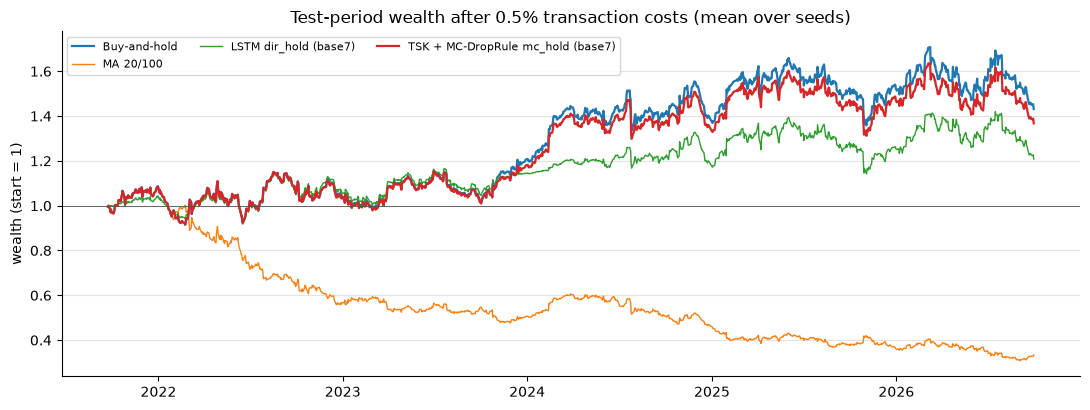

In [41]:
raw_close = stock_df['Close']
simple = raw_close.pct_change()
test_idx = pd.DatetimeIndex(np.concatenate([fold_arrays(k, 'base7', 'return')['dates_test'] for k in FOLD_IDS]))
test_fold = np.repeat(FOLD_IDS, 252)
r_test = simple.loc[test_idx].to_numpy()
date_key = test_idx.strftime('%Y-%m-%d')

strategies = {}                                              # name -> list of position arrays (one per seed)
strategies['Buy-and-hold'] = [np.ones(len(test_idx))]
strategies['MA 20/100'] = [ma_positions(raw_close, 20, 100).shift(1).loc[test_idx].to_numpy()]


def forecast_positions(preds, model, rule):
    """Positions of a forecast rule for each seed; thresholds chosen on each fold's validation block."""
    out = []
    for s, m in preds[preds.model == model].groupby('seed'):
        F, carry = np.zeros(len(test_idx)), 0.0
        for k in FOLD_IDS:
            va = m[(m.fold == k) & (m.part == 'val')]
            te = m[(m.fold == k) & (m.part == 'test')].set_index('target_date').loc[date_key[test_fold == k]]
            r_val = simple.loc[pd.DatetimeIndex(va.target_date)].to_numpy()
            if rule == 'dir_hold':
                sd = float(va.y_pred.std())
                c = best_on_validation(lambda c: hold_by_size(va.y_pred.to_numpy(), sd, c), C_GRID, r_val)
                Fk = hold_by_size(te.y_pred.to_numpy(), sd, c, start=carry)
            else:
                ratio = lambda g: (g.y_pred / g.mc_std.replace(0, np.nan)).fillna(0).to_numpy()
                k_ = best_on_validation(lambda q: hold_by_confidence(va.y_pred.to_numpy(), ratio(va), q), K_GRID, r_val)
                Fk = hold_by_confidence(te.y_pred.to_numpy(), ratio(te), k_, start=carry)
            F[test_fold == k] = Fk; carry = Fk[-1]
        out.append(F)
    return out


for f in ('base7', 'ext15'):
    p = predictions[('return', f)]
    for m in ('tsk', 'tsk_dr', 'mlp', 'lstm'):
        strategies[f'{RETURN_LABELS[m]} dir_hold ({f})'] = forecast_positions(p, m, 'dir_hold')
    strategies[f'TSK + MC-DropRule mc_hold ({f})'] = forecast_positions(p, 'tsk_mc', 'mc_hold')

daily = {name: np.mean([wealth_path(F, r_test)[0] for F in Fs], axis=0) for name, Fs in strategies.items()}
rows = []
for name, Fs in strategies.items():
    per = [dict(portfolio_stats(wealth_path(F, r_test)[0]), turnover=wealth_path(F, r_test)[1]) for F in Fs]
    lo, hi = sharpe_difference_ci(daily[name], daily['Buy-and-hold'])
    rows.append({'strategy': name, **pd.DataFrame(per).mean().to_dict(), 'Sharpe diff. vs buy-and-hold (95% CI)': f'[{lo:+.2f}, {hi:+.2f}]'})
trading = pd.DataFrame(rows).set_index('strategy')
display(trading.drop(columns='ann_return_%').round(3))

fig, ax = plt.subplots(figsize=(11, 4.2))
for name in ('Buy-and-hold', 'MA 20/100', 'LSTM dir_hold (base7)', 'TSK + MC-DropRule mc_hold (base7)'):
    ax.plot(test_idx, np.cumprod(1 + daily[name]), lw=1.6 if 'mc_hold' in name or name == 'Buy-and-hold' else 1.0, label=name)
ax.axhline(1, color='#52514e', lw=0.6)
ax.set(ylabel='wealth (start = 1)', title='Test-period wealth after 0.5% transaction costs (mean over seeds)')
ax.legend(fontsize=8, ncol=3); ax.grid(axis='y', color='#e4e3df'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Forecast-bottleneck-free framework.** The table below applies the MA 20/100 rule to the price series extended by one forecast close (section 4.5). Even the true next close (ST-ideal) raises the final wealth only from 0.333 to 0.382, and the model forecasts lower it slightly (0.297–0.301), whatever the model and input set. One extra price among the last 20 or 100 changes the moving averages very little, so for this rule even a perfect next-day forecast has little value.

In [42]:
prev_close_date = pd.Series(raw_close.index[:-1], index=raw_close.index[1:]).loc[test_idx]
d_prev = pd.DatetimeIndex(prev_close_date.to_numpy())
st = {'ST-basic (no forecast)': [extended_ma_positions(raw_close, d_prev)],
      'ST-ideal (true next close)': [extended_ma_positions(raw_close, d_prev, raw_close.loc[test_idx].to_numpy())]}
for f in ('base7', 'ext15'):
    p = predictions[('return', f)]
    for m in ('tsk', 'tsk_mc', 'mlp', 'lstm'):
        g = p[(p.model == m) & (p.part == 'test')]
        st[f'ST-{RETURN_LABELS[m]} ({f})'] = [
            extended_ma_positions(raw_close, d_prev, raw_close.loc[d_prev].to_numpy()
                                  * np.exp(gs.set_index('target_date').loc[date_key].y_pred.to_numpy()))
            for _, gs in g.groupby('seed')]
display(pd.DataFrame({name: pd.DataFrame([dict(portfolio_stats(wealth_path(F, r_test)[0]), turnover=wealth_path(F, r_test)[1])
                                          for F in Fs]).mean() for name, Fs in st.items()}).T
        [['final_wealth', 'sharpe', 'max_drawdown_%', 'turnover']].round(3))

,final_wealth,sharpe,max_drawdown_%,turnover
ST-basic (no forecast),0.333,-1.050,-71.635,59.0
ST-ideal (true next close),0.382,-0.911,-67.487,59.0
ST-TSK (base7),0.299,-1.161,-74.507,57.4
ST-TSK + MC-DropRule (base7),0.298,-1.164,-74.595,56.6
ST-MLP (base7),0.298,-1.166,-74.640,57.4
ST-LSTM (base7),0.300,-1.159,-74.465,59.0
ST-TSK (ext15),0.301,-1.154,-74.332,59.0
ST-TSK + MC-DropRule (ext15),0.301,-1.154,-74.332,59.0
ST-MLP (ext15),0.300,-1.157,-74.420,58.2
ST-LSTM (ext15),0.297,-1.169,-74.731,59.0


# 7. Discussion

## 7.1 Interpretability of the Rule Base

A TSK model can be read as a set of IF–THEN rules. The tables below describe the selected TSK models of fold 5 (seed 0) for the return task with `ext15` and for the volatility task with `base7`. For each rule they give its share of the firing strength over the test period, its three strongest antecedents (inputs whose rule centre lies at least 0.5 training SD from the mean, with a linguistic label), the forecast at the rule centre and the input with the largest consequent slope. The figure shows the membership functions of the VIX level and of WM's 20-day volatility.

**The rules describe market regimes.** In both models the rule centres separate calm from turbulent markets. In the return model, the VIX memberships form three groups, around 15, 22–27 and 43 VIX points. The two most active rules, R4 and R2 (55% of the test firing), describe a calm market with a low VIX and a low S&P 500 volatility and differ only in the volume change. R8 describes a falling market (negative S&P 500 returns, rising VIX), R7 a rising market, and R5 a sell-off in which WM has fallen behind the S&P 500. R3 and R6 describe the extreme turbulence of the training period and do not fire on the test period. In the volatility model, two rules for a low 20-day volatility (about 0.8%) take 63% of the test firing and forecast an absolute return of 0.77–0.80%, while six rules for a high volatility (1.8–2.7%) forecast 1.19–1.27%: the rule base encodes volatility clustering.

**The return forecasts are small and mostly mean-reverting.** At their centres, the active return rules forecast between −0.01% and +0.10%, and no slope moves the forecast by more than 0.1 percentage points per training SD of an input. R5 forecasts a rebound (+0.10%) after WM has underperformed the market, and in R8 a higher 5-day return of WM relative to the S&P 500 lowers the forecast: both describe a short-term reversal of WM's relative performance.

**Readability decreases with the number of inputs.** Each rule has a condition on every input, so with 15 inputs the tables can show only the strongest ones. The Gaussian sets also have a different centre and width in every rule, which is less transparent than a common partition of each input into a few labelled sets; this is the price of the cluster-based rule base of section 4.1.

Return task, ext15, fold 5: R=8, λw=0.3, λb=30


,test firing (%),IF (strongest antecedents),THEN forecast at the rule centre (%),largest slope (pp per SD)
rule,,,,
R4,28.934000,volume change is negative AND VIX level is low AND S&P 500 volatility is low,0.022,VIX level: +0.018
R2,26.606001,volume change is positive AND VIX level is low AND S&P 500 volatility is low,0.067,volume change: +0.012
R8,13.698000,VIX change is rising AND S&P 500 last return is negative AND S&P 500 5-day return is negative,-0.008,WM vs S&P 500 (5 days): -0.053
R5,12.673000,WM vs S&P 500 (5 days) is very negative AND RSG 5-day return is negative AND 20-day volatility is high,0.102,RSG last return: +0.059
R7,11.600000,S&P 500 last return is positive AND VIX change is falling AND last return is positive,0.088,RSG last return: +0.067
R1,6.489000,RSG 5-day return is positive AND 20-day volatility is high AND WM vs S&P 500 (5 days) is positive,0.058,return 2 days ago: -0.097
R3,0.000000,S&P 500 last return is very negative AND S&P 500 5-day return is very negative AND S&P 500 volatility is very high,0.475,return 4 days ago: -0.081
R6,0.000000,S&P 500 volatility is very high AND 20-day volatility is very high AND S&P 500 last return is very positive,-0.408,return 2 days ago: +0.053


Volatility task, base7, fold 5: R=8, λw=3, λb=0


,test firing (%),IF (strongest antecedents),THEN forecast at the rule centre (%),largest slope (pp per SD)
rule,,,,
R2,34.571999,volume change is negative AND 20-day volatility is low,0.768,20-day volatility: +0.008
R7,28.577999,volume change is positive AND 20-day volatility is low,0.797,20-day volatility: +0.007
R5,9.697000,last return is very negative AND volume change is positive AND 20-day volatility is high,1.225,last return: -0.023
R4,6.833000,return 4 days ago is very positive AND 20-day volatility is high AND return 5 days ago is negative,1.200,20-day volatility: +0.019
R3,6.556000,return 3 days ago is very positive AND return 4 days ago is negative AND 20-day volatility is high,1.230,20-day volatility: +0.011
R6,6.482000,return 2 days ago is very negative AND last return is positive AND 20-day volatility is high,1.188,return 2 days ago: -0.011
R1,4.237000,return 2 days ago is very positive AND return 3 days ago is very negative AND 20-day volatility is high,1.230,20-day volatility: +0.015
R8,3.046000,return 5 days ago is very positive AND 20-day volatility is very high AND last return is positive,1.266,return 5 days ago: +0.019


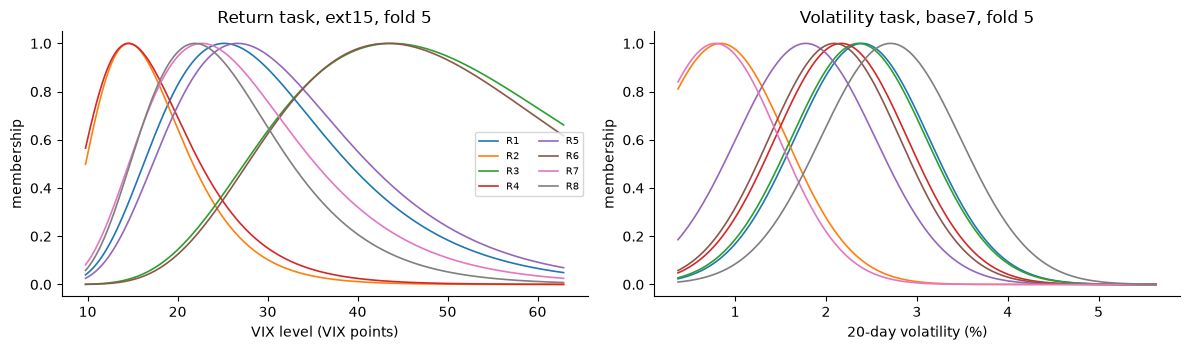

In [43]:
FEATURE_TEXT = {'return_lag_1': 'last return', 'return_lag_2': 'return 2 days ago', 'return_lag_3': 'return 3 days ago',
                'return_lag_4': 'return 4 days ago', 'return_lag_5': 'return 5 days ago', 'volatility_20': '20-day volatility',
                'volume_log_change': 'volume change', 'spx_r1': 'S&P 500 last return', 'spx_r5': 'S&P 500 5-day return',
                'spx_vol20': 'S&P 500 volatility', 'rsg_r1': 'RSG last return', 'rsg_r5': 'RSG 5-day return',
                'wm_rel5': 'WM vs S&P 500 (5 days)', 'vix_log': 'VIX level', 'vix_chg': 'VIX change'}
LEVEL_INPUTS = {'volatility_20', 'spx_vol20', 'vix_log'}


def linguistic(feature, z):
    """Linguistic label of a rule centre z (in training SDs)."""
    if feature in LEVEL_INPUTS:
        word = 'high' if z > 0 else 'low'
    elif feature == 'vix_chg':
        word = 'rising' if z > 0 else 'falling'
    else:
        word = 'positive' if z > 0 else 'negative'
    return ('very ' if abs(z) > 1.5 else '') + word


def explain_rules(task, features, k, seed=0, max_conditions=3):
    """Retrain the selected TSK of fold k and describe each rule by its strongest antecedents and its consequent."""
    d = fold_arrays(k, features, task)
    _, choices = search_results[(task, features)]
    cfg = json.loads(choices[(choices.model == 'tsk') & (choices.fold == k)].config.iloc[0])
    model, _ = fit_tsk(d['X_train'], d['z_train'], d['X_val'], d['z_val'], seed=seed, **cfg)
    centers, W, b = (t.detach().numpy().astype(float) for t in (model.centers, model.consequent_weights, model.consequent_bias))
    with torch.no_grad():
        firing = model.rule_weights(torch.as_tensor(d['X_test'], dtype=torch.float32)).numpy()
    cols, rows = FEATURE_SETS[features], []
    for r in range(len(b)):
        strongest = [j for j in np.argsort(-np.abs(centers[r])) if abs(centers[r, j]) >= 0.5][:max_conditions]
        slope = d['y_sd'] * W[r]
        j = int(np.argmax(np.abs(slope)))
        rows.append({'rule': f'R{r + 1}', 'test firing (%)': 100 * firing[:, r].mean(),
                     'IF (strongest antecedents)': ' AND '.join(f'{FEATURE_TEXT[cols[i]]} is {linguistic(cols[i], centers[r, i])}'
                                                              for i in strongest) or 'all inputs near their training mean',
                     'THEN forecast at the rule centre (%)': 100 * (d['y_mean'] + d['y_sd'] * (b[r] + W[r] @ centers[r])),
                     'largest slope (pp per SD)': f'{FEATURE_TEXT[cols[j]]}: {100 * slope[j]:+.3f}'})
    table = pd.DataFrame(rows).set_index('rule').sort_values('test firing (%)', ascending=False)
    return table, model, cfg


def plot_memberships(ax, model, task, features, k, feature):
    """Gaussian membership functions of one input over its central 99% training range, in original units."""
    j = FEATURE_SETS[features].index(feature)
    train = model_inputs.loc[:fold_bounds.loc[k].train_end, feature]
    x = np.linspace(train.quantile(0.005), train.quantile(0.995), 400)
    z = (x - train.mean()) / train.std(ddof=0)
    centers, sigmas = model.centers.detach().numpy()[:, j], model.sigmas.detach().numpy()[:, j]
    shown = np.exp(x) if feature == 'vix_log' else 100 * x
    for r in range(len(centers)):
        ax.plot(shown, np.exp(-0.5 * ((z - centers[r]) / sigmas[r]) ** 2), lw=1.2, label=f'R{r + 1}')
    ax.set(xlabel=FEATURE_TEXT[feature] + (' (VIX points)' if feature == 'vix_log' else ' (%)'), ylabel='membership',
           title=f"{'Return' if task == 'return' else 'Volatility'} task, {features}, fold {k}")
    ax.spines[['top', 'right']].set_visible(False)


pd.set_option('display.max_colwidth', 120)
rules_return, model_return, cfg_return = explain_rules('return', 'ext15', 5)
rules_vol, model_vol, cfg_vol = explain_rules('vol', 'base7', 5)
print('Return task, ext15, fold 5:', short(config_key(cfg_return)))
display(rules_return.round(3))
print('Volatility task, base7, fold 5:', short(config_key(cfg_vol)))
display(rules_vol.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_memberships(axes[0], model_return, 'return', 'ext15', 5, 'vix_log')
plot_memberships(axes[1], model_vol, 'vol', 'base7', 5, 'volatility_20')
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 7.2 Effect of the Hyperparameters

The figure below shows the pooled validation RMSE gain of every TSK configuration without DropRule over all five validation blocks, the data used for selection in section 5.2, as a function of $\lambda_b$, for $R \in \{2, 4, 8\}$ and $\lambda_w \in \{0.3, 3\}$.

**Return task.** Every configuration beats the random walk on the validation blocks, by 0.10–0.38%. The best configurations use four rules, $\lambda_w = 0.3$ and strong bias shrinkage: at $R = 4$ and $\lambda_w = 0.3$, raising $\lambda_b$ from 0 to 3 or more increases the gain from 0.27% to 0.38%. More rules or a larger slope penalty reduce the gain. With `base7`, the selection chooses $\lambda_b$ between 3 and 30 in every fold.

**Volatility task.** The gains are much larger (1.0–3.7%), and bias shrinkage reduces them, from about 3% at $\lambda_b \le 0.03$ to 1–3% at $\lambda_b \ge 3$. Here the rule biases carry the volatility level of each regime (section 7.1), which is the signal of the task, and pulling them together removes it. The selection reflects this: it chooses eight rules and $\lambda_b = 0$ in every fold, for both input sets.

The penalties therefore do what section 4.3 intends: they adapt the model to the strength of the signal, strong shrinkage when the signal is weak and none when it is strong.

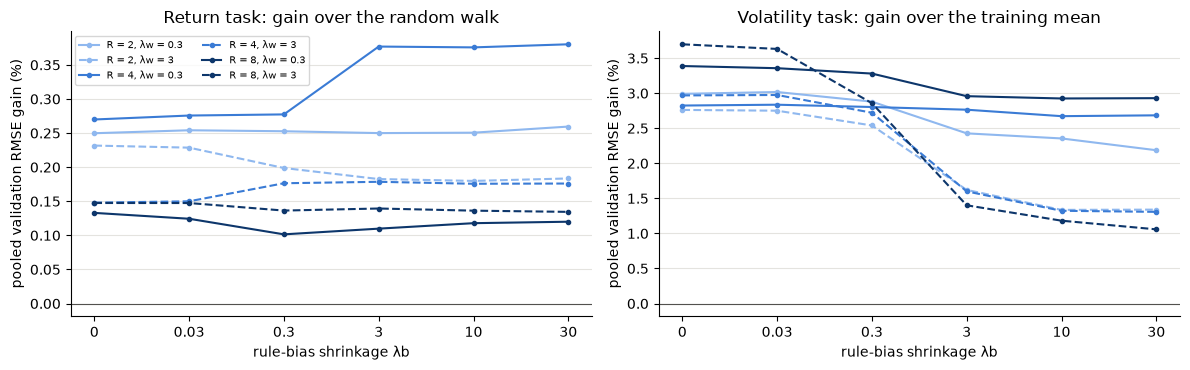

In [44]:
def sensitivity(task, features='base7'):
    """Pooled validation RMSE gain (%) of every TSK grid point (no DropRule) over all five validation blocks."""
    runs, _ = search_results[(task, features)]
    runs = runs[runs.model == 'tsk']
    folds = {k: fold_arrays(k, features, task) for k in FOLD_IDS}
    ref = {k: np.mean(d['y_val'] ** 2) if task == 'return' else np.mean((d['y_val'] - d['y_train'].mean()) ** 2)
           for k, d in folds.items()}
    block = runs.groupby(['config', 'fold']).val_mse.mean().reset_index()
    block['ref'] = block.fold.map(ref)
    pooled = block.groupby('config')[['val_mse', 'ref']].mean()
    out = pd.DataFrame([json.loads(c) for c in pooled.index])
    out['gain'] = 100 * (1 - np.sqrt(pooled.val_mse.to_numpy() / pooled.ref.to_numpy()))
    return out


L2B = (0.0, 0.03, 0.3, 3.0, 10.0, 30.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, task, title in ((axes[0], 'return', 'Return task: gain over the random walk'),
                        (axes[1], 'vol', 'Volatility task: gain over the training mean')):
    s = sensitivity(task)
    for rules, color in ((2, '#8fb8ef'), (4, '#3a7bd5'), (8, '#0d366b')):
        for l2_w, style in ((0.3, '-'), (3.0, '--')):
            g = s[(s.n_rules == rules) & (s.l2_w == l2_w)].set_index('l2_b').loc[list(L2B), 'gain']
            ax.plot(range(len(L2B)), g.to_numpy(), style, color=color, marker='o', ms=3, lw=1.5,
                    label=f'R = {rules}, λw = {l2_w:g}')
    ax.axhline(0, color='#52514e', lw=0.8)
    ax.set_xticks(range(len(L2B)), [f'{v:g}' for v in L2B])
    ax.set(xlabel='rule-bias shrinkage λb', ylabel='pooled validation RMSE gain (%)', title=title)
    ax.grid(axis='y', color='#e4e3df'); ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 7.3 Strengths and Weaknesses of the TSK Approach

**Strengths.**
- *Controlled conservatism.* The slope and bias penalties set directly how far the forecast may move away from the training mean. Under a low signal-to-noise ratio this matters more than flexibility (section 6.1), and the same penalties step aside when the signal is strong (section 7.2).
- *Interpretability.* The rule base describes market regimes with linguistic conditions and local linear effects (section 7.1).
- *Uncertainty at no extra training cost.* MC-DropRule turns the trained rule base into a measure of disagreement between rules, which gave the best prediction-based trading rule (section 6.4).
- *Compactness.* The selected models have 88–368 parameters (4–8 rules), against about 1,000–5,200 for the selected MLP and LSTM networks.

**Weaknesses.**
- *Few rules.* With product memberships over many inputs, the firing strengths become very local, so the rule base must stay small; two of the eight `ext15` rules carry no test firing.
- *Dependence on the initialisation.* The k-means centres change with the seed, and so do the rules.
- *Readability with many inputs*, as discussed in section 7.1.
- *Small gains.* The advantage over the random walk on returns is not significant, and on the volatility task the networks have a lower MAE (section 6.3).

## 7.4 Relation to Published Results

Our results agree with the literature on the predictability of stock returns. The daily returns of a large, liquid stock are close to unpredictable from their own past, as the weak form of the efficient-market hypothesis states (Fama, 1970): with `base7` no model beats the random walk. Return forecasts that use other information typically have a small, often negative, out-of-sample $R^2$ (Welch & Goyal, 2008); the best `ext15` model reduces the RMSE of the random walk by 0.16%, an out-of-sample $R^2$ of about 0.3%. In contrast, the size of returns is predictable because volatility clusters (Engle, 1982; Bollerslev, 1986), and the gains of the volatility task are about ten times larger.

## 7.5 Limitations

- **One stock and one test period.** All results come from a single large, low-volatility stock and five test years (2021–2026); they may not transfer to more volatile stocks or other periods.
- **Selection optimism.** The validation gains of the selected configurations (section 7.2) are larger than their test gains (section 6.1): choosing the best of 54 configurations favours those that fit the validation blocks by chance, so the size of a small validation advantage should not be taken at face value.
- **Trading assumptions.** Trades are made at the adjusted close, with a fixed transaction rate of 0.5% and without slippage or short-selling costs.
- **News data.** GDELT 1.0 changes its coverage and coding over time, its dates are event dates rather than publication times, and only seven daily indicators are used.
- **Uncertainty measure.** The MC-DropRule SD measures disagreement between rules; it is not a calibrated predictive interval.
- **Search space.** The grids are small (54 TSK configurations), and other initialisations and training algorithms of TSK systems were not explored.

# 8. Future Work

**Method.**
- *Rule bases that grow with the data.* Evolving neuro-fuzzy systems such as DENFIS (Kasabov & Song, 2002) add rules when new regimes appear, instead of fixing the rule count in advance; rules for the turbulent regimes of section 7.1 would then be created only when needed.
- *Calibrated uncertainty.* The MC-DropRule spread could be calibrated on the validation blocks, for example by conformal prediction, to give predictive intervals that can size positions instead of only filtering trades.
- *Joint return and volatility models.* The volatility task is far more predictable than the return task. A TSK model with two outputs, or a return model that uses the forecast volatility as an input or as a scale for its forecasts, would combine the two.

**Data.**
- *Transfer across stocks.* Training one rule base on several waste-management and utility stocks, or pre-training on the market and fine-tuning on WM, would give the model more data for the same weak signal.
- *Timed news.* GDELT 2.0 records articles every 15 minutes, which would allow news published before the US close to be used on the same day.

**Other applications.** Many forecasting problems share the low signal-to-noise setting of daily returns, for example electricity prices, retail demand and sensor-based fault detection. In such problems, a regularised, interpretable model that knows when its forecast is uncertain, and abstains then, can be more useful than a more flexible one.

# 9. Conclusion

This report studied next-day forecasting and trading of Waste Management (WM) stock with a first-order TSK neuro-fuzzy system trained with DropRule, regularised for a low signal-to-noise ratio, and with MC-DropRule as a measure of model uncertainty. On five test years (2021–2026):

- **RQ1.** With WM's own price and volume history, no model beats the random walk on next-day returns. TSK comes closest and ranks above MLP and LSTM, because its penalties keep the forecasts close to the training mean, where they add the least noise.
- **RQ2.** With S&P 500, RSG and VIX inputs, the TSK variants are the only models that beat the random walk (by up to 0.16%, not significantly), and they are significantly more accurate than MLP and LSTM. World-news events from GDELT make every model less accurate.
- **RQ3.** The size of the next-day return is far more predictable than its sign. TSK reduces the RMSE of the absolute return by 1.7% relative to EWMA and is significantly more accurate than both networks with `base7`.
- **RQ4.** No strategy beats buy-and-hold after transaction costs. The best prediction-based strategy trades only when the MC-DropRule forecast is confident (final wealth 1.37 and Sharpe ratio 0.42, against 1.43 and 0.47 for buy-and-hold). Without prediction, the MA 20/100 rule loses two thirds of its wealth, and even a perfect next-day forecast adds little to it.

For a stock whose daily returns are this close to unpredictable, the value of the model lies less in its point forecasts than in knowing when not to act on them: in penalties that keep the forecasts small, and in an uncertainty measure that limits trading to the forecasts on which the rules agree.

# References

- Ang, K. K., & Quek, C. (2006). Stock trading using RSPOP: A novel rough set-based neuro-fuzzy approach. *IEEE Transactions on Neural Networks*, 17(5), 1301–1315.
- Atsalakis, G. S., & Valavanis, K. P. (2009). Surveying stock market forecasting techniques – Part II: Soft computing methods. *Expert Systems with Applications*, 36(3), 5932–5941.
- Bollen, J., Mao, H., & Zeng, X. (2011). Twitter mood predicts the stock market. *Journal of Computational Science*, 2(1), 1–8.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Brock, W., Lakonishok, J., & LeBaron, B. (1992). Simple technical trading rules and the stochastic properties of stock returns. *Journal of Finance*, 47(5), 1731–1764.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- Fama, E. F. (1970). Efficient capital markets: A review of theory and empirical work. *Journal of Finance*, 25(2), 383–417.
- Gal, Y., & Ghahramani, Z. (2016). Dropout as a Bayesian approximation: Representing model uncertainty in deep learning. In *Proceedings of the 33rd International Conference on Machine Learning* (pp. 1050–1059).
- Gu, S., Kelly, B., & Xiu, D. (2020). Empirical asset pricing via machine learning. *Review of Financial Studies*, 33(5), 2223–2273.
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780.
- J.P. Morgan/Reuters. (1996). *RiskMetrics – Technical document* (4th ed.). New York: J.P. Morgan.
- Jang, J.-S. R. (1993). ANFIS: Adaptive-network-based fuzzy inference system. *IEEE Transactions on Systems, Man, and Cybernetics*, 23(3), 665–685.
- Kasabov, N. K., & Song, Q. (2002). DENFIS: Dynamic evolving neural-fuzzy inference system and its application for time-series prediction. *IEEE Transactions on Fuzzy Systems*, 10(2), 144–154.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *Proceedings of the 3rd International Conference on Learning Representations*.
- Leetaru, K., & Schrodt, P. A. (2013). GDELT: Global data on events, location, and tone, 1979–2012. Paper presented at the *International Studies Association Annual Convention*, San Francisco.
- Lo, A. W. (2004). The adaptive markets hypothesis. *Journal of Portfolio Management*, 30(5), 15–29.
- Mamdani, E. H., & Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy logic controller. *International Journal of Man-Machine Studies*, 7(1), 1–13.
- Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708.
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15, 1929–1958.
- Takagi, T., & Sugeno, M. (1985). Fuzzy identification of systems and its applications to modeling and control. *IEEE Transactions on Systems, Man, and Cybernetics*, SMC-15(1), 116–132.
- Tetlock, P. C. (2007). Giving content to investor sentiment: The role of media in the stock market. *Journal of Finance*, 62(3), 1139–1168.
- Welch, I., & Goyal, A. (2008). A comprehensive look at the empirical performance of equity premium prediction. *Review of Financial Studies*, 21(4), 1455–1508.
- Whaley, R. E. (2000). The investor fear gauge. *Journal of Portfolio Management*, 26(3), 12–17.
- Wu, D., Yuan, Y., Huang, J., & Tan, Y. (2020). Optimize TSK fuzzy systems for regression problems: Minibatch gradient descent with regularization, DropRule, and AdaBound (MBGD-RDA). *IEEE Transactions on Fuzzy Systems*, 28(5), 1003–1015.
- Zadeh, L. A. (1965). Fuzzy sets. *Information and Control*, 8(3), 338–353.